# **Proyecto: Selección del mejor frame con parámetros posturales para la estimación de pose en perros**
### Introducción a la Ciencia de Datos
*Alumno: Norman O. Guzmán Chaboya*

Para analizar la conducta de un perro a partir de video, se estima su pose en cada frame con SuperAnimal-Quadruped y se eligen los frames cuya pose es más confiable. Hasta ahora, esa elección se basa solo en la *likelihood* de los keypoints, que es la confianza del propio modelo: un frame puede tener una likelihood alta y, aun así, un esqueleto imposible.

En este proyecto se construye un score que combina la likelihood con los ángulos posturales de Ferres et al. y con proporciones de longitud de hueso, y se ajusta con Optuna para elegir los frames con menor error real respecto a la corrección manual. Las preguntas de investigación son:

1. ¿Agregar los ángulos de Ferres y las proporciones de hueso al score actual elige frames con menor error real que la likelihood sola?
2. ¿Cuánto aporta cada grupo de parámetros, y cada parámetro, al activarlo o desactivarlo?
3. ¿Cambia ese aporte entre razas con morfologías distintas?

Para saber si las respuestas dependen de la calidad de los videos, el análisis se repite en tres baterías de seis videos, dos por raza: los de calidad alta, media y baja según la exploración.

A lo largo del *notebook* se realiza lo siguiente:

1. Datos.
2. Exploración.
3. Preprocesamiento y partición.
4. Modelado.
5. Evaluación.
6. Conclusiones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy

import warnings
import glob
import json
import os
import re
import optuna

from scipy.stats import rankdata, spearmanr, wilcoxon
plt.style.use('bmh')

SEMILLA = 42
os.makedirs('figures', exist_ok=True)   # figuras (png) y tablas (csv) para el reporte

warnings.filterwarnings('ignore', category=RuntimeWarning)

In [2]:
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scipy       ", scipy.__version__)
print("optuna      ", optuna.__version__)

numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
scipy        1.18.1
optuna       4.5.0


## 1. Datos

Los datos provienen del proyecto de pose canina del grupo: videos de 10 razas del grupo 1 de la FCI (perros de pastor y boyeros), con 12 videos por raza. Cada video se procesó con SuperAnimal-Quadruped adaptado al propio video, y de cada uno se extrajeron 24 frames que se corrigieron a mano. Por video hay tres fuentes:

* `1_superanimal`: un JSON con la predicción de todos los frames del video. Por frame trae hasta dos detecciones, cada una con su caja (`[x, y, ancho, alto]`), el score de la caja y 39 keypoints (x, y, likelihood). Es la única fuente con frames consecutivos y con likelihood. Se dispone del JSON de los 120 videos, pero a partir de la sección 2.2 solo se usan los de las tres razas elegidas.
* `1_dlc`: los 24 frames seleccionados, con la predicción de los 24 keypoints del esquema reducido.
* `1_dlc_hand_corrected`: los mismos frames corregidos a mano. Un punto vacío indica que el anotador lo consideró ocluido.

Se definen los 24 keypoints, las aristas del esqueleto y las funciones de lectura de las tres fuentes:

In [3]:
RUTA = 'data'
SA39 = ['nose', 'upper_jaw', 'lower_jaw', 'mouth_end_right', 'mouth_end_left', 'right_eye', 'right_earbase',
        'right_earend', 'right_antler_base', 'right_antler_end', 'left_eye', 'left_earbase', 'left_earend',
        'left_antler_base', 'left_antler_end', 'neck_base', 'neck_end', 'throat_base', 'throat_end', 'back_base',
        'back_end', 'back_middle', 'tail_base', 'tail_end', 'front_left_thai', 'front_left_knee', 'front_left_paw',
        'front_right_thai', 'front_right_knee', 'front_right_paw', 'back_left_paw', 'back_left_thai',
        'back_right_thai', 'back_left_knee', 'back_right_knee', 'back_right_paw', 'belly_bottom',
        'body_middle_right', 'body_middle_left']

KP24 = ['nose', 'lower_jaw', 'right_eye', 'right_earbase', 'right_earend', 'left_eye', 'left_earbase', 'left_earend',
        'neck_end', 'throat_base', 'tail_base', 'tail_end', 'front_left_thai', 'front_left_knee', 'front_left_paw',
        'front_right_thai', 'front_right_knee', 'front_right_paw', 'back_left_paw', 'back_left_thai',
        'back_right_thai', 'back_left_knee', 'back_right_knee', 'back_right_paw']

K = {k: i for i, k in enumerate(KP24)}

EXTREMIDADES = ['front_left', 'front_right', 'back_left', 'back_right']
ESQUELETO = [('nose', 'lower_jaw'), ('nose', 'right_eye'), ('nose', 'left_eye'), ('right_eye', 'right_earbase'),
             ('right_earbase', 'right_earend'), ('left_eye', 'left_earbase'), ('left_earbase', 'left_earend'),
             ('lower_jaw', 'throat_base'), ('throat_base', 'neck_end'), ('neck_end', 'tail_base'), ('tail_base', 'tail_end')]
ESQUELETO += [(f'{e}_{a}', f'{e}_{b}') for e in EXTREMIDADES for a, b in [('thai', 'knee'), ('knee', 'paw')]]
ESQUELETO += [('neck_end', f'front_{s}_thai') for s in ('left', 'right')] + [('tail_base', f'back_{s}_thai') for s in ('left', 'right')]

RAZAS = sorted(os.listdir(f'{RUTA}/1_dlc'))

 # CSVs de DLC
def leer_dlc(ruta):
    tabla = pd.read_csv(ruta, header=[0, 1, 2], index_col=[0, 1, 2])
    partes = list(dict.fromkeys(tabla.columns.get_level_values(1)))
    X = tabla.to_numpy(dtype=float).reshape(len(tabla), len(partes), 2)[:, [partes.index(k) for k in KP24]]
    frames = np.array([int(re.search(r'(\d+)', i[2]).group(1)) - 1 for i in tabla.index])
    return frames, X

# JSONs con datos posturales y de bbox precalculados a través de SuperAnimal-Quadruped fine-tuning
def leer_superanimal(raza, video):
    ruta = glob.glob(f'{RUTA}/1_superanimal/{raza}/{video}_superanimal*.json')[0]
    datos = json.load(open(ruta))
    P = np.array([d['bodyparts'] for d in datos])[:, 0][:, [SA39.index(k) for k in KP24]]
    cajas = np.array([d['bboxes'] for d in datos])[:, 0]
    score = np.array([d['bbox_scores'] for d in datos])
    return P, cajas, score

# Predicciones
def leer_video(raza, video):
    f_pred, X_pred = leer_dlc(f'{RUTA}/1_dlc/{raza}/{video}/CollectedData_sys.csv')
    f_corr, X_corr = leer_dlc(f'{RUTA}/1_dlc_hand_corrected/{raza}/{video}/CollectedData_sys.csv')
    comunes = np.intersect1d(f_pred, f_corr)
    return comunes, X_pred[np.isin(f_pred, comunes)], X_corr[np.isin(f_corr, comunes)], len(f_pred) - len(comunes)

Se revisa qué hay en cada fuente: el número de videos por raza, los frames anotados y si el video tiene JSON. Además, se verifica que los frames del CSV seleccionado sean copias de la predicción del JSON y que la corrección use los mismos frames que la selección:

In [4]:
inventario, verificacion = [], []

for raza in RAZAS:
    
    for video in sorted(os.listdir(f'{RUTA}/1_dlc/{raza}'), key=lambda v: int(v.split('_')[-1])):
        comunes, X_pred, X_corr, sin_par = leer_video(raza, video)
        tiene_json = bool(glob.glob(f'{RUTA}/1_superanimal/{raza}/{video}_superanimal*.json'))
        inventario.append({'raza': raza, 'video': video, 'frames emparejados': len(comunes), 'frames sin par': sin_par, 'JSON': tiene_json})
        
        if tiene_json:
            P, cajas, score = leer_superanimal(raza, video)
            dif = np.hypot(*(P[comunes, :, :2] - X_pred).transpose(2, 0, 1))
            verificacion.append({'raza': raza, 'video': video, 'frames del video': len(P), 'puntos': np.isfinite(dif).sum(),
                                 'puntos distintos': (dif > 0.01).sum(), 'diferencia mediana (px)': np.nanmedian(dif)})

inventario = pd.DataFrame(inventario)
verificacion = pd.DataFrame(verificacion)

print(f"{len(inventario)} videos de {inventario.raza.nunique()} razas; {inventario.JSON.sum()} con JSON")

print(f"Videos con frames sin par entre la selección y la corrección: {(inventario['frames sin par'] > 0).sum()}")

print(f"Puntos del CSV seleccionado idénticos al JSON (img N = posición N - 1): "
      f"{1 - verificacion['puntos distintos'].sum() / verificacion['puntos'].sum():.2%}; "
      f"distintos: {verificacion['puntos distintos'].sum()} en {(verificacion['puntos distintos'] > 0).sum()} videos")

print(f"Frames por video con JSON: {verificacion['frames del video'].min()} a {verificacion['frames del video'].max()}")

resumen_inventario = inventario.groupby('raza').agg(videos=('video', 'count'), frames_emparejados=('frames emparejados', 'sum'),
                                                    frames_sin_par=('frames sin par', 'sum'), videos_con_JSON=('JSON', 'sum'))
resumen_inventario = resumen_inventario.join(verificacion.groupby('raza').agg(puntos_distintos=('puntos distintos', 'sum'),
                                                                              videos_con_diferencias=('puntos distintos', lambda d: (d > 0).sum())))
resumen_inventario

120 videos de 10 razas; 120 con JSON
Videos con frames sin par entre la selección y la corrección: 26
Puntos del CSV seleccionado idénticos al JSON (img N = posición N - 1): 97.78%; distintos: 1458 en 27 videos
Frames por video con JSON: 185 a 57035


,videos,frames_emparejados,frames_sin_par,videos_con_JSON,puntos_distintos,videos_con_diferencias
raza,,,,,,
Australian_Cattle_Dog,12,286,2,12,10,1
Australian_Kelpie,12,256,32,12,75,3
Beauceron,12,269,19,12,18,4
Border_Collie,12,246,42,12,506,2
Chien_de_Berger_Belge_Malinois,12,288,0,12,6,2
German_Shepherd_Dog,12,283,5,12,3,2
Pumi,12,269,19,12,2,2
Schipperke,12,276,12,12,605,4
Shetland_Sheepdog,12,288,0,12,16,4


Hay 120 videos de 10 razas, 12 por raza, con entre 246 y 288 frames emparejados por raza, y JSON para todos ellos. La regla que liga ambas fuentes se cumple: el frame `imgN` del CSV corresponde a la posición N - 1 del JSON, y 97.78% de los puntos son idénticos. Los 1,458 puntos que difieren se reparten en 27 videos; en las tres razas que se usan en el resto del análisis solo hay 29, aislados en 7 videos, así que la correspondencia se cumple donde importa. No se investigó la causa de las diferencias en las otras siete razas, porque de ellas solo se usan los CSV. En 26 videos la corrección no conserva todos los frames de la selección (hasta 42 frames sin par en Border Collie), así que la predicción y la corrección se emparejan por el número de frame y no por su posición en el archivo. Los videos van de 185 a 57,035 frames.

## 2. Exploración

La exploración sirve para elegir tres razas y dos videos por raza, con el fin de que el ruido que agregan las condiciones de cada video no oculte el efecto de los parámetros. Para comparar, se necesitan los ángulos de Ferres et al. (2022) y las longitudes de las extremidades, que se definen sobre los 24 keypoints. Ferres mide los ángulos respecto a la cruz (*withers*), que SuperAnimal no tiene: se aproxima con `neck_end`. Su mentón es `lower_jaw` y sus codos, los puntos `*_knee`. Como en Ferres, el perro se refleja para que todos miren hacia la izquierda y se usa el lado que mira a la cámara:

In [5]:
TAU = 0.5   # umbral de likelihood del score actual

# Ángulo de v1 a v2, NaN si falta algún punto
def angulo(v1, v2):
    return np.degrees(np.arctan2(v1[..., 0] * v2[..., 1] - v1[..., 1] * v2[..., 0], (v1 * v2).sum(-1)))

# Ángulo interno
def angulo_vertice(a, b, c):
    return np.abs(angulo(a - b, c - b))

# Refleja en x para que la cabeza quede a la izquierda de la base de la cola
def orientar(X):
    X = X.copy()
    if np.nanmean(X[[K['nose'], K['left_earbase'], K['right_earbase']], 0]) > X[K['tail_base'], 0]:
        X[:, 0] = -X[:, 0]
    return X

# Lado con más puntos visibles de oreja y extremidades, de acuerdo con lo hecho en el artículo pero con las orejas
def lado_visible(X):
    return max(('left', 'right'), key=lambda s: np.isfinite(X[[K[k] for k in KP24 if s in k], 0]).sum())

# Los siete ángulos posturales de Ferres donde positivo = levantado o extendido
def angulos_ferres(X):
    X = orientar(X)
    s = lado_visible(X)
    
    cruz, cola0, cola1 = X[K['neck_end']], X[K['tail_base']], X[K['tail_end']]
    pata_del, pata_tras = X[K[f'front_{s}_paw']], X[K[f'back_{s}_paw']]
    dorsal, apoyo = cola0 - cruz, pata_tras - pata_del
    
    return {'peso': angulo(apoyo, dorsal),
            'cola': angulo(dorsal, cola1 - cola0),
            'cabeza': angulo(apoyo, X[K['nose']] - cruz),
            'oreja': angulo(X[K[f'{s}_earbase']] - X[K['nose']], X[K[f'{s}_earend']] - X[K[f'{s}_earbase']]),
            'boca': angulo_vertice(X[K['nose']], X[K[f'{s}_earbase']], X[K['lower_jaw']]),
            'pata_delantera': angulo_vertice(pata_del, X[K[f'front_{s}_knee']], cruz),
            'pata_trasera': angulo_vertice(pata_tras, X[K[f'back_{s}_knee']], cola0)}

def longitudes(X):
    # Largo de cada extremidad (muslo-rodilla + rodilla-pata) y longitud corporal (neck_end-tail_base)
    L = {e: np.hypot(*(X[K[f'{e}_thai']] - X[K[f'{e}_knee']])) + np.hypot(*(X[K[f'{e}_knee']] - X[K[f'{e}_paw']]))
         for e in EXTREMIDADES}
    L['cuerpo'] = np.hypot(*(X[K['neck_end']] - X[K['tail_base']]))
    
    return L

    

### 2.1. Elección de las razas

Para cada uno de los 120 videos se comparan la predicción y la corrección en los frames que comparten. Se miden la proporción de puntos borrados por oclusión, movidos y malos (borrados o desplazados más de 5% de la diagonal del esqueleto), la proporción de frames corregidos en los que se pueden calcular los siete ángulos de Ferres y cada ángulo por separado, la proporción de frames con al menos tres extremidades completas y qué tan horizontal es el cuerpo en la imagen, como aproximación a la vista lateral, que la comparación de longitudes de hueso supone:

In [6]:
def comparar_video(raza, video):
    
    comunes, X_pred, X_corr, sin_par = leer_video(raza, video)
    extension = np.nanmax(X_pred, 1) - np.nanmin(X_pred, 1)
    diag = np.hypot(extension[:, 0], extension[:, 1])
    borrado = np.isnan(X_corr[:, :, 0])
    desplazamiento = np.hypot(*(X_pred - X_corr).transpose(2, 0, 1)) / diag[:, None]
    ferres = pd.DataFrame([angulos_ferres(x) for x in X_corr])
    completas = np.array([[np.isfinite(x[[K[f'{e}_{p}'] for p in ('thai', 'knee', 'paw')], 0]).all() for e in EXTREMIDADES] for x in X_corr])
    
    # para ubicar el cuerpo, los puntos ocluidos se toman de la predicción
    X_llena = np.where(np.isnan(X_corr), X_pred, X_corr)   
    
    eje = np.abs(X_llena[:, K['neck_end'], 0] - X_llena[:, K['tail_base'], 0]) / extension[:, 0]
    
    return {'raza': raza, 'video': video, 'frames emparejados': len(comunes), 'frames sin par': sin_par,
            'borrados (%)': 100 * borrado.mean(), 'movidos (%)': 100 * ((desplazamiento > 0.001) & ~borrado).mean(),
            'malos (%)': 100 * (borrado | (desplazamiento > 0.05)).mean(),
            'Ferres 7/7 (%)': 100 * ferres.notna().all(axis=1).mean(), 'Ferres por ángulo (%)': 100 * ferres.notna().mean().mean(),
            '3+ patas completas (%)': 100 * (completas.sum(axis=1) >= 3).mean(), 'eje horizontal': np.nanmedian(eje)}

videos = pd.DataFrame([comparar_video(r, v) for r, v in inventario[['raza', 'video']].to_numpy()])
videos['lateral'] = videos['eje horizontal'] > 0.5

razas = videos.groupby('raza').agg({'malos (%)': 'mean', 'borrados (%)': 'mean', 'Ferres 7/7 (%)': 'mean',
                                    'Ferres por ángulo (%)': 'mean', '3+ patas completas (%)': 'mean',
                                    'lateral': 'sum', 'frames sin par': 'sum'}).rename(columns={'lateral': 'videos laterales'})


# Puntaje de calidad
criterios = {'Ferres 7/7 (%)': False, 'Ferres por ángulo (%)': False, 'videos laterales': False, 'frames sin par': True}
razas['suma de lugares'] = sum(razas[c].rank(ascending=asc) for c, asc in criterios.items())
razas = razas.sort_values('suma de lugares')
RAZAS_SEL = list(razas.index[:3])

print("Razas elegidas:", ", ".join(RAZAS_SEL))

razas.round(2)

Razas elegidas: German_Shepherd_Dog, Shetland_Sheepdog, Australian_Cattle_Dog


,malos (%),borrados (%),Ferres 7/7 (%),Ferres por ángulo (%),3+ patas completas (%),videos laterales,frames sin par,suma de lugares
raza,,,,,,,,
German_Shepherd_Dog,42.34,30.08,27.81,60.11,31.98,6,5,7.0
Shetland_Sheepdog,44.62,33.43,21.53,50.99,20.83,5,0,11.5
Australian_Cattle_Dog,30.32,22.62,16.12,59.74,42.65,4,2,15.5
Chien_de_Berger_Belge_Malinois,34.82,22.02,19.44,54.86,43.06,2,0,16.5
Beauceron,36.29,23.79,23.37,56.41,53.40,1,19,21.5
Pumi,49.97,30.10,11.59,47.06,37.73,4,19,27.0
Border_Collie,48.52,27.17,20.99,50.69,31.94,1,42,29.0
Australian_Kelpie,48.54,31.87,17.29,46.98,32.13,2,32,30.0
Schipperke,52.48,32.18,6.19,43.29,30.05,2,12,31.0


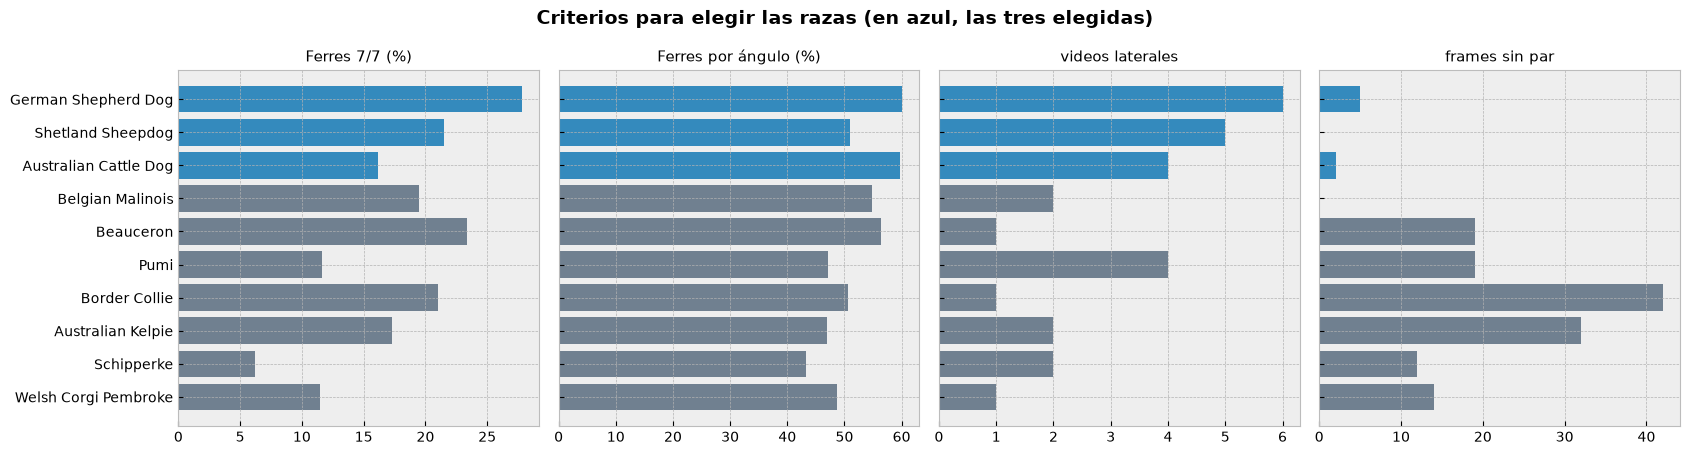

In [7]:
with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), sharey=True)
    colores = ['#348ABD' if r in RAZAS_SEL else 'slategrey' for r in razas.index]
    nombres = [r.replace('_', ' ').replace('Chien de Berger Belge', 'Belgian') for r in razas.index]
    
    for ax, c in zip(axes, criterios):
        ax.barh(nombres, razas[c], color=colores)
        ax.set_title(c, fontsize=11)
        
    axes[0].invert_yaxis()
    fig.suptitle('Criterios para elegir las razas (en azul, las tres elegidas)', fontweight='bold', fontsize=14)
    plt.tight_layout()
    
    plt.show()

In [8]:
fig.savefig('figures/breed_criteria.png', dpi=300, bbox_inches='tight')

Las tres razas elegidas son German Shepherd Dog, Shetland Sheepdog y Australian Cattle Dog. German Shepherd Dog obtiene el mejor puntaje porque tiene la mayor proporción de frames con los siete ángulos de Ferres (27.81%) y el mayor número de videos laterales (6). Shetland Sheepdog tiene 5 videos laterales y ningún frame sin par, y su pelaje largo pone a prueba los puntos ocluidos. Australian Cattle Dog tiene la menor proporción de puntos malos (30.32%) y casi la misma cobertura por ángulo que German Shepherd Dog (59.74%). Belgian Malinois queda cerca (16.5 contra 15.5) porque tampoco tiene frames sin par, pero solo tiene 2 videos laterales. Las tres razas difieren en morfología: un pastor grande de patas largas, uno pequeño de pelo largo y un boyero compacto, lo que permite responder la tercera pregunta de investigación.

### 2.2. Elección de los videos

Entre los 36 videos de las tres razas se forman tres baterías de seis videos, dos por raza. Se descartan los que tienen menos de 20 frames emparejados y, entre los demás, se ordenan por la suma de lugares en vista lateral, ángulos de Ferres completos y extremidades completas. La batería alta toma los dos primeros de cada raza, la media los dos del centro de la lista y la baja los dos últimos. La batería alta es la que se usa en la exploración y el preprocesamiento; las otras dos permiten comprobar si los resultados se mantienen en videos más difíciles. Del JSON se agregan la duración del video, la likelihood media de los 24 keypoints y la proporción de frames en los que el detector encontró una segunda caja:

In [9]:
def resumen_json(raza, video):
    P, cajas, score = leer_superanimal(raza, video)
    
    return {'frames del video': len(P), 'likelihood media': np.nanmean(P[:, :, 2]),
            'frames con 2 cajas (%)': 100 * (score[:, 1] > 0).mean(), 'frames sin caja (%)': 100 * (score[:, 0] <= 0).mean()}

candidatos = videos[videos.raza.isin(RAZAS_SEL)].copy()
candidatos = candidatos.join(pd.DataFrame([resumen_json(r, v) for r, v in candidatos[['raza', 'video']].to_numpy()], index=candidatos.index))
aptos = candidatos['frames emparejados'] >= 20
lugares = candidatos[aptos].groupby('raza')[['eje horizontal', 'Ferres 7/7 (%)', '3+ patas completas (%)']].rank(ascending=False)
candidatos.loc[aptos, 'suma de lugares'] = lugares.sum(axis=1)

BATERIAS = {'alta': [], 'media': [], 'baja': []}

for raza, t in candidatos[aptos].sort_values('suma de lugares', kind='stable').groupby('raza'):
    orden, n = t.video.tolist(), len(t)
    
    # Dos primeros, dos del centro y dos últimos de cada raza
    for bateria, elegidos in [('alta', orden[:2]), ('media', orden[n // 2 - 1:n // 2 + 1]), ('baja', orden[-2:])]:
        BATERIAS[bateria] += [[raza, v] for v in elegidos]
        
VIDEOS_SEL = BATERIAS['alta']   # exploración y preprocesamiento
TODOS = [(b, r, v) for b, lista in BATERIAS.items() for r, v in lista]


for b, lista in BATERIAS.items():
    print(f"Batería {b}:", ", ".join(v for _, v in lista))

columnas = ['raza', 'frames del video', 'frames emparejados', 'eje horizontal', 'Ferres 7/7 (%)', '3+ patas completas (%)',
            'malos (%)', 'likelihood media', 'frames con 2 cajas (%)']

videos_elegidos = candidatos.set_index('video').loc[[v for _, _, v in TODOS], columnas]
videos_elegidos.insert(0, 'batería', [b for b, _, _ in TODOS])

videos_elegidos.round(2)


Batería alta: Australian_Cattle_Dog_8, Australian_Cattle_Dog_9, German_Shepherd_Dog_2, German_Shepherd_Dog_11, Shetland_Sheepdog_7, Shetland_Sheepdog_10
Batería media: Australian_Cattle_Dog_6, Australian_Cattle_Dog_1, German_Shepherd_Dog_9, German_Shepherd_Dog_4, Shetland_Sheepdog_4, Shetland_Sheepdog_9
Batería baja: Australian_Cattle_Dog_7, Australian_Cattle_Dog_5, German_Shepherd_Dog_7, German_Shepherd_Dog_6, Shetland_Sheepdog_11, Shetland_Sheepdog_2


,batería,raza,frames del video,frames emparejados,eje horizontal,Ferres 7/7 (%),3+ patas completas (%),malos (%),likelihood media,frames con 2 cajas (%)
video,,,,,,,,,,
Australian_Cattle_Dog_8,alta,Australian_Cattle_Dog,453,23,0.54,39.13,69.57,26.09,0.60,7.73
Australian_Cattle_Dog_9,alta,Australian_Cattle_Dog,1088,24,0.41,41.67,45.83,21.18,0.70,26.56
German_Shepherd_Dog_2,alta,German_Shepherd_Dog,429,24,0.62,33.33,70.83,15.45,0.81,0.47
German_Shepherd_Dog_11,alta,German_Shepherd_Dog,1781,24,0.63,37.50,37.50,25.35,0.69,5.90
Shetland_Sheepdog_7,alta,Shetland_Sheepdog,882,24,0.57,58.33,45.83,26.91,0.68,16.55
Shetland_Sheepdog_10,alta,Shetland_Sheepdog,577,24,0.52,91.67,62.50,26.04,0.78,4.33
Australian_Cattle_Dog_6,media,Australian_Cattle_Dog,633,24,0.41,20.83,41.67,44.97,0.19,24.17
Australian_Cattle_Dog_1,media,Australian_Cattle_Dog,399,24,0.37,20.83,41.67,36.81,0.61,57.89
German_Shepherd_Dog_9,media,German_Shepherd_Dog,284,24,0.43,62.50,41.67,32.47,0.70,7.39


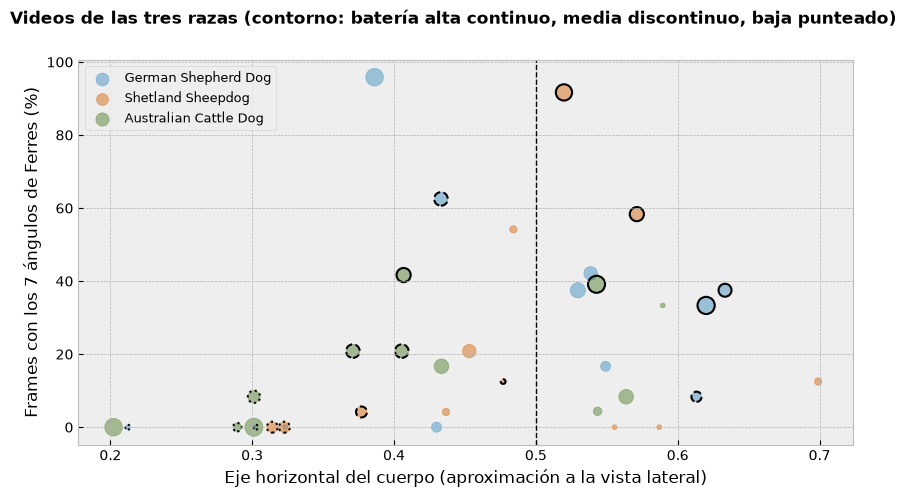

In [10]:
with plt.style.context('bmh'):
    fig, ax = plt.subplots(figsize=(10, 5))
    estilo = {'alta': ('black', '-'), 'media': ('black', '--'), 'baja': ('black', ':')}
    
    for raza, color in zip(RAZAS_SEL, ['#348ABD', '#D55E00', '#467821']):
        t = candidatos[candidatos.raza == raza]
        ax.scatter(t['eje horizontal'], t['Ferres 7/7 (%)'], s=12 + 2 * t['3+ patas completas (%)'], color=color,
                   alpha=0.45, label=raza.replace('_', ' '))
    
    # Contorno según la batería: continuo alta, discontinuo media, punteado baja
    
    for b, r, v in TODOS:
        fila = candidatos.set_index('video').loc[v]
        ax.scatter(fila['eje horizontal'], fila['Ferres 7/7 (%)'], s=12 + 2 * fila['3+ patas completas (%)'],
                   facecolor='none', edgecolor=estilo[b][0], linestyle=estilo[b][1], linewidth=1.5)
    ax.axvline(0.5, color='black', linestyle='--', linewidth=1)
    ax.set_xlabel('Eje horizontal del cuerpo (aproximación a la vista lateral)')
    ax.set_ylabel('Frames con los 7 ángulos de Ferres (%)')
    ax.legend(loc='upper left', fontsize=9)
    fig.suptitle('Videos de las tres razas (contorno: batería alta continuo, media discontinuo, baja punteado)', fontweight='bold', fontsize=12)
    
    plt.show()

In [11]:
fig.savefig('figures/video_selection.png', dpi=300, bbox_inches='tight')

La batería alta está formada por Australian Cattle Dog 8 y 9, German Shepherd Dog 2 y 11 y Shetland Sheepdog 7 y 10; la media, por Australian Cattle Dog 6 y 1, German Shepherd Dog 9 y 4 y Shetland Sheepdog 4 y 9, y la baja, por Australian Cattle Dog 7 y 5, German Shepherd Dog 7 y 6 y Shetland Sheepdog 11 y 2. Todos tienen 24 frames emparejados, salvo Australian Cattle Dog 8, con 23. La calidad baja de forma clara de una batería a otra. En la alta, cinco de los seis videos son laterales y entre 33% y 92% de sus frames tienen los siete ángulos de Ferres; en la media, la vista lateral solo se da en German Shepherd Dog 4 y los siete ángulos van de 4% a 63%, y en la baja ningún video es lateral (eje horizontal de 0.21 a 0.32) y cinco de los seis no tienen un solo frame con los siete ángulos. La proporción de puntos malos pasa de 15% a 27% en la alta a entre 32% y 68% en las otras dos. Sin embargo, la likelihood media no sigue esa caída: en la batería baja va de 0.55 a 0.75, casi como en la alta (0.60 a 0.81), es decir, el modelo está igual de seguro en videos donde se equivoca mucho más. En la batería alta, Australian Cattle Dog 9 queda bajo el umbral de vista lateral (0.41), pero sus ángulos completos lo ponen por delante de los otros videos de su raza. Las segundas cajas son frecuentes en Australian Cattle Dog 1 (57.9%), German Shepherd Dog 7 (52.5%) y German Shepherd Dog 4 (43.1%), lo que indica personas u otros objetos cerca del perro.

### 2.3. Un caso en el que la likelihood falla

Para motivar el uso de parámetros posturales, se busca en los videos elegidos un frame que el score actual, (keypoints válidos / 24) × likelihood media de los válidos con τ = 0.5, coloque entre el cuarto mejor de su video, pero cuya predicción tenga una extremidad desproporcionada que la corrección manual repara. Se grafica solo el esqueleto, sin la imagen, para ver si tiene forma de perro:

In [12]:
def score_actual(P, tau=TAU):
    # Score de referencia: fracción de keypoints sobre el umbral por su likelihood media
    validos = P[..., 2] >= tau
    media = np.where(validos.any(-1), np.nanmean(np.where(validos, P[..., 2], np.nan), -1), 0)
    
    return validos.mean(-1) * media

def razon_patas(X):
    # Largo de cada extremidad entre la mediana de las cuatro; NaN si hay menos de tres completas
    patas = np.array([longitudes(X)[e] for e in EXTREMIDADES])
    
    return patas / np.nanmedian(patas) if np.isfinite(patas).sum() >= 3 else np.full(4, np.nan)

casos = []
for raza, video in VIDEOS_SEL:
    P, cajas, score = leer_superanimal(raza, video)
    comunes, X_pred, X_corr, _ = leer_video(raza, video)
    lugar = pd.Series(score_actual(P)).rank(pct=True, ascending=True).to_numpy()
    
    for i, f in enumerate(comunes):
        r_pred, r_corr = razon_patas(X_pred[i]), razon_patas(X_corr[i])
        
        if np.isnan(r_pred).all():
            continue
        e = np.nanargmax(np.abs(np.log(r_pred)))   # extremidad más desproporcionada en la predicción
        casos.append({'raza': raza, 'video': video, 'frame': f, 'i': i, 'percentil del score': 100 * lugar[f],
                      'extremidad': EXTREMIDADES[e], 'razón predicha': r_pred[e], 'razón corregida': r_corr[e]})

casos = pd.DataFrame(casos)

# Solo frames donde el anotador conservó esa extremidad, para comparar el mismo hueso
casos['reparación'] = np.abs(np.log(casos['razón predicha'])) - np.abs(np.log(casos['razón corregida']))
caso = casos[casos['percentil del score'] >= 75].dropna().sort_values('reparación', ascending=False).iloc[0]
caso[['video', 'frame', 'percentil del score', 'extremidad', 'razón predicha', 'razón corregida']]


video                  Shetland_Sheepdog_7
frame                                  590
percentil del score              80.952381
extremidad                      front_left
razón predicha                    0.653837
razón corregida                   0.853843
Name: 103, dtype: object

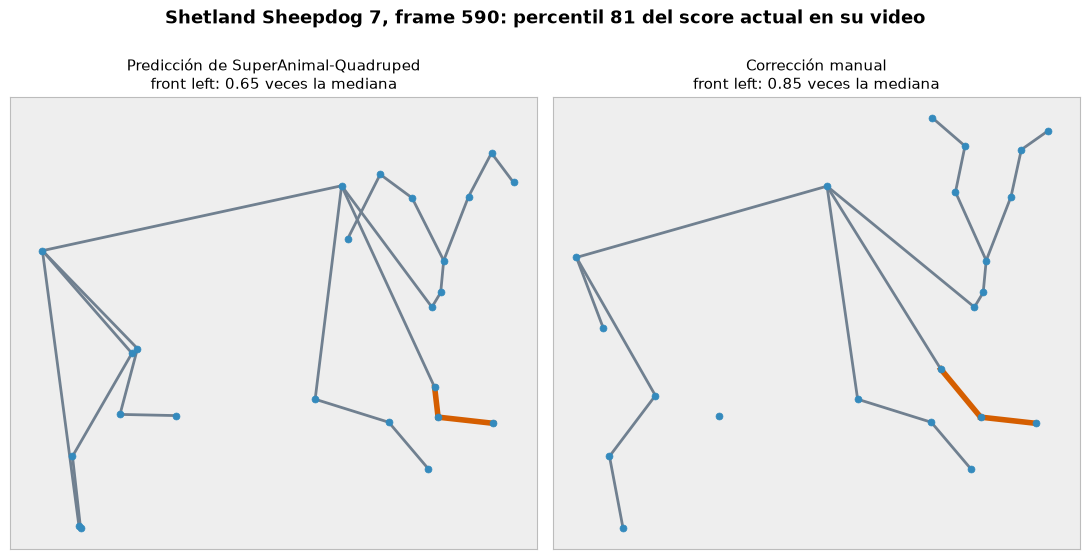

In [13]:
def dibujar_esqueleto(ax, X, color='#348ABD', resaltar=(), invertir=True):
    
    # Esqueleto sin la imagen; las aristas de `resaltar` en naranja
    for a, b in ESQUELETO:
        
        if np.isfinite(X[[K[a], K[b]]]).all():
            caliente = any(e in a and e in b for e in resaltar)
            ax.plot(*X[[K[a], K[b]]].T, color='#D55E00' if caliente else 'slategrey', linewidth=4 if caliente else 2)
    
    ax.scatter(*X.T, s=25, color=color, zorder=3)
    
    if invertir:   # el eje y de la imagen crece hacia abajo
        ax.invert_yaxis()
        
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

comunes, X_pred, X_corr, _ = leer_video(caso.raza, caso.video)
x_p, x_c = X_pred[int(caso.i)], X_corr[int(caso.i)]

peor = caso.extremidad

with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharex=True, sharey=True)
    
    for ax, X, titulo in [(axes[0], x_p, 'Predicción de SuperAnimal-Quadruped'), (axes[1], x_c, 'Corrección manual')]:
        dibujar_esqueleto(ax, X, resaltar=(peor,), invertir=(ax is axes[0]))
        ax.set_title(f"{titulo}\n{peor.replace('_', ' ')}: {razon_patas(X)[EXTREMIDADES.index(peor)]:.2f} veces la mediana", fontsize=11)
    
    fig.suptitle(f"{caso.video.replace('_', ' ')}, frame {int(caso.frame)}: percentil {caso['percentil del score']:.0f} del score actual en su video",
                 fontweight='bold', fontsize=13, y=1.04)   # sobre los títulos de dos líneas
    plt.tight_layout()
    
    plt.show()

In [14]:
fig.savefig('figures/likelihood_failure_case.png', dpi=300, bbox_inches='tight')


El frame 590 de Shetland Sheepdog 7 está en el percentil 81 del score actual de su video, es decir, entre los frames que el criterio actual preferiría, pero su pata delantera izquierda mide 0.65 veces la mediana de las cuatro. La corrección movió el muslo de esa pata y la dejó en 0.85, además de reubicar `neck_end`, la oreja derecha y la punta de la cola, y de borrar el muslo y la rodilla traseros izquierdos por oclusión. La likelihood no detecta este error porque cada punto, por separado, parece confiable; la proporción entre extremidades sí lo muestra. También se observa que la razón dentro del frame no llega a 1 aun después de corregir: la perspectiva cambia la longitud aparente de las patas, por lo que conviene compararlas además con la referencia de cada extremidad en el propio video.

### 2.4. Hallazgos que orientan el preprocesamiento

Se revisan tres aspectos en los seis videos elegidos: cuántas veces falta `neck_end`, del que dependen cuatro ángulos de Ferres, y si en esos frames está disponible `throat_base`; si los keypoints que se mueven más rápido necesitan más corrección, y con qué frecuencia los ángulos de las patas cambian más de 90° entre frames consecutivos, algo físicamente imposible en 1/30 s:

In [15]:

filas, rapidez = [], []

for raza, video in VIDEOS_SEL:
    P, cajas, score = leer_superanimal(raza, video)
    comunes, X_pred, X_corr, _ = leer_video(raza, video)
    borrado = np.isnan(X_corr[:, :, 0])
    diag = np.hypot(cajas[:, 2], cajas[:, 3])
    
    # Velocidad de cada keypoint en el frame anotado: diferencia central, en fracción de la diagonal de la caja
    velocidad = np.hypot(*(P[np.minimum(comunes + 1, len(P) - 1), :, :2] - P[np.maximum(comunes - 1, 0), :, :2]).transpose(2, 0, 1)) / 2 / diag[comunes, None]
    
    correccion = np.hypot(*(X_pred - X_corr).transpose(2, 0, 1)) / diag[comunes, None]
    rapidez.append(pd.DataFrame({'velocidad': velocidad[~borrado], 'corrección': correccion[~borrado]}))
    
    # Saltos de los ángulos de las patas en todo el video, con todos los puntos y solo con los que superan el umbral
    salto = {}
    
    for nombre, X_todo in [('sin umbral', P[..., :2]), ('con τ', np.where(P[..., 2:3] >= TAU, P[..., :2], np.nan))]:
        patas = pd.DataFrame([angulos_ferres(x) for x in X_todo])[['pata_delantera', 'pata_trasera']]
        salto[nombre] = (patas.diff().abs() > 90).any(axis=1).mean()
    
    filas.append({'video': video, 'neck_end borrado (%)': 100 * borrado[:, K['neck_end']].mean(),
                  'throat_base disponible cuando falta (%)': 100 * (~borrado[borrado[:, K['neck_end']], K['throat_base']]).mean() if borrado[:, K['neck_end']].any() else np.nan,
                  'frames con salto > 90° sin umbral (%)': 100 * salto['sin umbral'],
                  'frames con salto > 90° con τ (%)': 100 * salto['con τ']})
hallazgos = pd.DataFrame(filas).set_index('video')

rapidez = pd.concat(rapidez, ignore_index=True)
rapidez['cuartil de velocidad'] = pd.qcut(rapidez['velocidad'], 4, labels=['1 (lento)', '2', '3', '4 (rápido)'])

arrastre = rapidez.groupby('cuartil de velocidad', observed=True).agg(
    velocidad_mediana=('velocidad', 'median'), movidos=('corrección', lambda c: (c > 0.001).mean()), correccion_media=('corrección', 'mean'))

r = spearmanr(rapidez['velocidad'], rapidez['corrección'])

print(f"Spearman entre velocidad y corrección: {r.statistic:.2f} (p = {r.pvalue:.1g}, {len(rapidez)} puntos)")

display_arrastre = (100 * arrastre).round(2).rename(columns={'velocidad_mediana': 'velocidad mediana (% diag/frame)',
                                                             'movidos': 'movidos (%)', 'correccion_media': 'corrección media (% diag)'})

print(display_arrastre.to_string())

hallazgos.round(1)

Spearman entre velocidad y corrección: 0.15 (p = 9e-17, 2865 puntos)
                      velocidad mediana (% diag/frame)  movidos (%)  corrección media (% diag)
cuartil de velocidad                                                                          
1 (lento)                                         0.27        30.54                       0.81
2                                                 0.71        36.45                       0.85
3                                                 1.50        39.53                       1.19
4 (rápido)                                        4.98        46.51                       2.70


,neck_end borrado (%),throat_base disponible cuando falta (%),frames con salto > 90° sin umbral (%),frames con salto > 90° con τ (%)
video,,,,
Australian_Cattle_Dog_8,0.0,NaN,5.5,0.7
Australian_Cattle_Dog_9,29.2,100.0,4.3,0.2
German_Shepherd_Dog_2,37.5,100.0,1.4,0.0
German_Shepherd_Dog_11,0.0,NaN,1.2,0.2
Shetland_Sheepdog_7,16.7,100.0,14.4,0.5
Shetland_Sheepdog_10,0.0,NaN,1.9,0.0


El anotador borró `neck_end` en 16.7% a 37.5% de los frames de tres videos, y en todos esos frames `throat_base` sigue disponible, lo que justifica estimar `neck_end` a partir de él. Los puntos que se mueven más rápido necesitan más corrección: en el cuartil más rápido se movió ~46% de los puntos, contra 30.54% en el más lento, y la corrección media se triplica (de 0.81% a 2.70% de la diagonal). La correlación de Spearman es baja (0.15) pero significativa, por lo que la velocidad se reserva para un grupo temporal que se probará después de los ángulos y las proporciones. Con todos los puntos, entre 1.2% y 14.4% de los frames tienen un salto mayor a 90 grados en algún ángulo de pata; con el umbral τ la proporción baja a 0.7% o menos, en parte porque el umbral elimina los puntos erróneos y en parte porque deja el ángulo sin calcular.

## 3. Preprocesamiento y partición

### 3.1. Puntos ausentes

Un keypoint se trata como ausente si su likelihood está bajo el umbral τ o si cae fuera de la caja de la detección, por ejemplo sobre una persona. Para ver qué tanto coincide este criterio con el anotador, se compara, en los frames corregidos, con los puntos que el anotador borró por oclusión:

In [16]:
def puntos_validos(P, cajas, tau=TAU):
    # Válido: likelihood >= tau y dentro de la caja [x, y, ancho, alto]
    x, y = P[..., 0], P[..., 1]
    dentro = ((x >= cajas[:, None, 0]) & (x <= cajas[:, None, 0] + cajas[:, None, 2]) &
              (y >= cajas[:, None, 1]) & (y <= cajas[:, None, 1] + cajas[:, None, 3]))
    
    return (P[..., 2] >= tau) & dentro

acuerdo = []

for raza, video in VIDEOS_SEL:
    P, cajas, score = leer_superanimal(raza, video)
    comunes, X_pred, X_corr, _ = leer_video(raza, video)
    validos = puntos_validos(P, cajas)
    acuerdo.append(pd.DataFrame({'ausente por el criterio': ~validos[comunes].ravel(),
                                 'borrado por el anotador': np.isnan(X_corr[:, :, 0]).ravel(),
                                 'fuera de la caja': (~puntos_validos(P, cajas, tau=0))[comunes].ravel()}))

acuerdo = pd.concat(acuerdo, ignore_index=True)

print(f"Puntos fuera de la caja: {acuerdo['fuera de la caja'].mean():.1%}")

cruce = 100 * pd.crosstab(acuerdo['borrado por el anotador'], acuerdo['ausente por el criterio'], normalize='index')
cruce.round(1)

Puntos fuera de la caja: 0.3%


ausente por el criterio,False,True
borrado por el anotador,,
False,93.3,6.7
True,74.8,25.2


Solo 0.3% de los puntos cae fuera de la caja, por lo que la condición de la caja casi no cambia el resultado. El umbral τ coincide poco con el anotador: de los puntos que el anotador borró por oclusión, solo 25.2% tiene likelihood bajo 0.5, mientras que 6.7% de los que conservó queda bajo el umbral. SuperAnimal asigna likelihood alta a muchos puntos que no se ven, lo que refuerza la necesidad de una señal que no dependa solo de la confianza del modelo. Como τ define qué puntos entran en los parámetros, su valor se ajusta con Optuna junto con los pesos.

### 3.2. Normalización

Para que los parámetros no dependan del tamaño del perro ni de su posición en la imagen, las coordenadas se centran en la caja y se dividen entre su diagonal, y el perro se refleja para que mire hacia la izquierda. Cuando falta `neck_end`, se estima a partir de `throat_base` con el desplazamiento mediano entre ambos en el propio video, una conversión lineal como la que Ferres usó cuando la cruz no era visible. Ese desplazamiento se calcula solo con las predicciones, sin ver la corrección:

In [17]:
# Centra en la caja, divide entre su diagonal y orienta la cabeza a la izquierda
def normalizar(X, caja):
    centro = np.array([caja[0] + caja[2] / 2, caja[1] + caja[3] / 2])
    
    return orientar((X - centro) / np.hypot(caja[2], caja[3]))
    
# Desplazamiento mediano throat_base deriva en neck_end en el video, con frames donde ambos son válidos
def desplazamiento_cuello(P, cajas, tau=TAU):
    
    validos = puntos_validos(P, cajas, tau)
    ambos = validos[:, K['neck_end']] & validos[:, K['throat_base']]
    N = np.array([normalizar(P[t, :, :2], cajas[t]) for t in np.flatnonzero(ambos)])
    
    return np.median(N[:, K['neck_end']] - N[:, K['throat_base']], axis=0) if len(N) else np.full(2, np.nan)

# Si falta neck_end y hay throat_base, lo estima con el desplazamiento del video
def completar_cuello(N, desplazamiento):
    
    N = N.copy()
    if np.isnan(N[K['neck_end']]).any() and np.isfinite(N[K['throat_base']]).all():
        N[K['neck_end']] = N[K['throat_base']] + desplazamiento
    return N

recuperacion, poses = [], {r: [] for r in RAZAS_SEL}

for raza, video in VIDEOS_SEL:
    P, cajas, score = leer_superanimal(raza, video)
    comunes, X_pred, X_corr, _ = leer_video(raza, video)
    d_cuello = desplazamiento_cuello(P, cajas)
    N_corr = [normalizar(X_corr[i], cajas[f]) for i, f in enumerate(comunes)]
    antes = pd.DataFrame([angulos_ferres(n) for n in N_corr]).notna().all(axis=1).mean()
    despues = pd.DataFrame([angulos_ferres(completar_cuello(n, d_cuello)) for n in N_corr]).notna().all(axis=1).mean()
    recuperacion.append({'video': video, 'Ferres 7/7 antes (%)': 100 * antes, 'Ferres 7/7 con neck_end estimado (%)': 100 * despues})
    poses[raza] += N_corr
    
recuperacion = pd.DataFrame(recuperacion).set_index('video')
recuperacion.round(1)

,Ferres 7/7 antes (%),Ferres 7/7 con neck_end estimado (%)
video,,
Australian_Cattle_Dog_8,39.1,39.1
Australian_Cattle_Dog_9,41.7,50.0
German_Shepherd_Dog_2,33.3,33.3
German_Shepherd_Dog_11,37.5,37.5
Shetland_Sheepdog_7,58.3,66.7
Shetland_Sheepdog_10,91.7,91.7


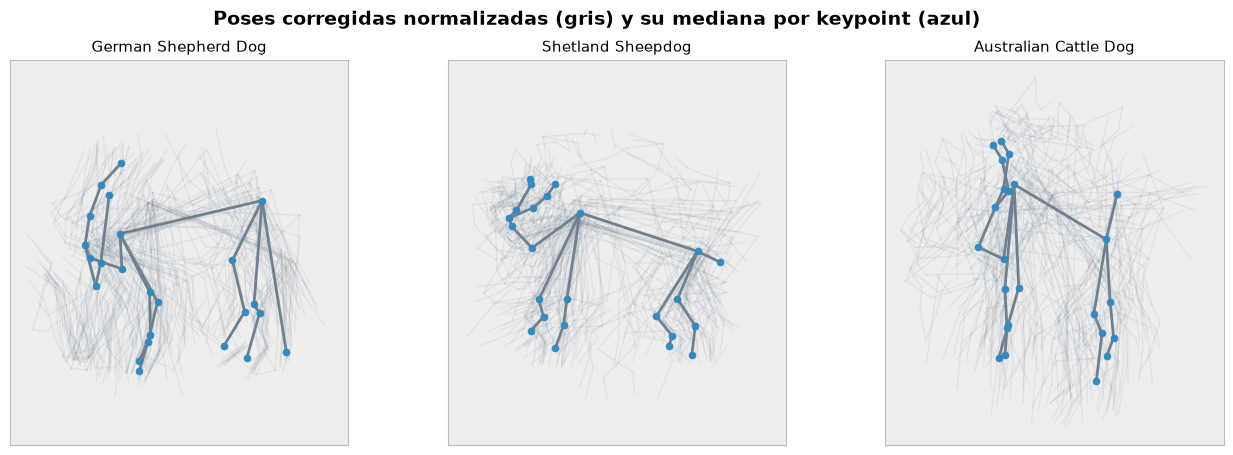

In [18]:
with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
    
    for ax, raza in zip(axes, RAZAS_SEL):
        
        for n in poses[raza]:
            
            for a, b in ESQUELETO:
                
                if np.isfinite(n[[K[a], K[b]]]).all():
                    ax.plot(*n[[K[a], K[b]]].T, color='slategrey', alpha=0.1, linewidth=1)
        
        dibujar_esqueleto(ax, np.nanmedian(np.array(poses[raza]), axis=0), invertir=False)
        ax.set_title(raza.replace('_', ' '), fontsize=11)
    
    axes[0].invert_yaxis()   # los ejes son compartidos: se invierte una sola vez
    fig.suptitle('Poses corregidas normalizadas (gris) y su mediana por keypoint (azul)', fontweight='bold', fontsize=14)
    
    plt.show()

In [19]:
fig.savefig('figures/normalized_poses.png', dpi=300, bbox_inches='tight')

La estimación de `neck_end` recupera frames con los siete ángulos en Australian Cattle Dog 9 (de 41.7% a 50.0%) y en Shetland Sheepdog 7 (de 58.3% a 66.7%). En German Shepherd Dog 2 no cambia, porque en los 9 frames donde falta `neck_end` también falta `tail_base`, del que dependen los ángulos de peso, cola y pata trasera; ese punto no tiene un sustituto cercano en el esquema de 24 keypoints. Las poses medianas de German Shepherd Dog y Shetland Sheepdog tienen forma de perro de perfil, con la cabeza a la izquierda y las cuatro patas debajo del cuerpo, lo que confirma que la normalización y la orientación funcionan. La de Australian Cattle Dog es más estrecha y tiene el cuerpo inclinado, por la vista menos lateral de su video 9; las proporciones de hueso serán menos confiables en esa raza, lo que se revisará en la evaluación por raza.

### 3.3. Partición

Las predicciones de SuperAnimal-Quadruped se generaron sin ver ninguna corrección manual: el modelo se adaptó a cada video con sus propias predicciones como etiquetas, por lo que las correcciones son una referencia independiente. La única fuga posible está en el ajuste del score, y para evitarla dentro de cada batería se deja fuera un video a la vez: los pesos del score y sus umbrales se ajustan con los frames corregidos de cinco videos y se evalúan en el sexto. Todo lo que se calcula por video, como el desplazamiento del cuello o las longitudes de referencia de las extremidades, usa solo las predicciones de ese video, que están disponibles sin anotación, de modo que nunca se usa la corrección del video que se evalúa. Las referencias de cada video son la mediana de cada extremidad en los frames donde sus tres puntos son válidos:

In [20]:
def referencia_video(P, cajas, tau=TAU):
    # Longitud normalizada de referencia de cada extremidad: mediana en los frames donde sus tres puntos son válidos
    validos = puntos_validos(P, cajas, tau)
    ref = {}
    
    for e in EXTREMIDADES:
        ids = [K[f'{e}_{p}'] for p in ('thai', 'knee', 'paw')]
        frames = np.flatnonzero(validos[:, ids].all(1))
        ref[e] = np.median([longitudes(normalizar(P[t, :, :2], cajas[t]))[e] for t in frames]) if len(frames) else np.nan
        ref[f'frames {e}'] = len(frames)
    
    return ref

pliegues = []

for bateria, raza, video in TODOS:
    P, cajas, score = leer_superanimal(raza, video)
    ref = referencia_video(P, cajas)
    pliegues.append({'video de prueba': video, 'batería': bateria, 'raza': raza, 'videos de entrenamiento': len(BATERIAS[bateria]) - 1,
                     'frames de prueba': len(leer_video(raza, video)[0]),
                     **{f'referencia {e}': ref[e] for e in EXTREMIDADES},
                     'frames para la referencia (mín.)': min(ref[f'frames {e}'] for e in EXTREMIDADES)})

pliegues = pd.DataFrame(pliegues).set_index('video de prueba')
pliegues.round(3)

,batería,raza,videos de entrenamiento,frames de prueba,referencia front_left,referencia front_right,referencia back_left,referencia back_right,frames para la referencia (mín.)
video de prueba,,,,,,,,,
Australian_Cattle_Dog_8,alta,Australian_Cattle_Dog,5,23,0.222,0.184,0.262,0.266,191
Australian_Cattle_Dog_9,alta,Australian_Cattle_Dog,5,24,0.211,0.222,0.180,0.210,543
German_Shepherd_Dog_2,alta,German_Shepherd_Dog,5,24,0.225,0.190,0.184,0.149,339
German_Shepherd_Dog_11,alta,German_Shepherd_Dog,5,24,0.161,0.219,0.197,0.256,818
Shetland_Sheepdog_7,alta,Shetland_Sheepdog,5,24,0.138,0.178,0.148,0.192,395
Shetland_Sheepdog_10,alta,Shetland_Sheepdog,5,24,0.166,0.166,0.149,0.187,513
Australian_Cattle_Dog_6,media,Australian_Cattle_Dog,5,24,0.207,0.224,0.209,0.249,101
Australian_Cattle_Dog_1,media,Australian_Cattle_Dog,5,24,0.149,0.152,0.174,0.152,123
German_Shepherd_Dog_9,media,German_Shepherd_Dog,5,24,0.177,0.137,0.153,0.144,152


Se forman 18 pliegues, seis por batería, con 23 o 24 frames de prueba cada uno. Las referencias de cada extremidad se calculan sin usar ninguna corrección y van de 0.137 a 0.301 de la diagonal de la caja. En la batería alta se apoyan en al menos 191 frames por video, pero en las otras dos hay menos frames con los tres puntos de una extremidad válidos, y en la baja el mínimo baja a 48 (Shetland Sheepdog 2), así que las referencias son menos estables justo donde las vistas no son laterales. Dentro de un mismo video las extremidades no miden lo mismo: en German Shepherd Dog 2, la delantera izquierda mide 0.225 y la trasera derecha 0.149, por la perspectiva y por cuál lado está más cerca de la cámara. Por eso la proporción de hueso se compara con la referencia de la misma extremidad en el propio video y no con un valor fijo por raza.

## 4. Modelado

### 4.1. Error real de cada frame

Para comparar scores se necesita saber qué tan buena es la predicción de cada frame anotado de las tres baterías. El error de un frame es la fracción de sus 24 keypoints que son malos: borrados por el anotador por oclusión o desplazados más de 5% de la diagonal de la caja. Como medida secundaria se usa el error normalizado medio (NME) de los puntos que el anotador conservó. Además, se revisa en qué percentil del score actual están los frames anotados, para saber si la corrección cubre solo frames que el criterio actual ya prefería:

In [21]:
def error_frames(X_pred, X_corr, cajas_f, umbral=0.05):
    
    # Fracción de keypoints malos (borrados o desplazados > 5% de la diagonal) y NME de los conservados
    diag = np.hypot(cajas_f[:, 2], cajas_f[:, 3])[:, None]
    borrado = np.isnan(X_corr[:, :, 0])
    d = np.hypot(*(X_pred - X_corr).transpose(2, 0, 1)) / diag
    
    return (borrado | (d > umbral)).mean(axis=1), np.nanmean(np.where(borrado, np.nan, d), axis=1)

anotados, JSON = [], {}

for bateria, raza, video in TODOS:
    P, cajas, score = leer_superanimal(raza, video)
    JSON[video] = (P, cajas)
    comunes, X_pred, X_corr, _ = leer_video(raza, video)
    error, nme = error_frames(X_pred, X_corr, cajas[comunes])
    percentil = pd.Series(score_actual(P)).rank(pct=True).to_numpy()[comunes]
    anotados.append(pd.DataFrame({'batería': bateria, 'raza': raza, 'video': video, 'frame': comunes, 'error': error, 'nme': nme,
                                  'percentil L': 100 * percentil}))
anotados = pd.concat(anotados, ignore_index=True)

for b, t in anotados.groupby('batería', sort=False):
    print(f"Batería {b}: {len(t)} frames anotados; error medio {t.error.mean():.3f}, NME medio {t.nme.mean():.4f}; "
          f"percentil del score actual: mediana {t['percentil L'].median():.0f}, de {t['percentil L'].min():.0f} a {t['percentil L'].max():.0f}")

resumen_anotados = anotados.groupby(['batería', 'video'], sort=False).agg(frames=('frame', 'count'), error_medio=('error', 'mean'), error_min=('error', 'min'),
                                          error_max=('error', 'max'), NME_medio=('nme', 'mean'))

resumen_anotados.round(3)

Batería alta: 143 frames anotados; error medio 0.219, NME medio 0.0148; percentil del score actual: mediana 81, de 8 a 100
Batería media: 144 frames anotados; error medio 0.430, NME medio 0.0709; percentil del score actual: mediana 79, de 4 a 100
Batería baja: 144 frames anotados; error medio 0.448, NME medio 0.1521; percentil del score actual: mediana 83, de 9 a 100


frames  error_medio  error_min  error_max  \
batería video                                                                
alta    Australian_Cattle_Dog_8      23        0.254      0.042      0.500   
        Australian_Cattle_Dog_9      24        0.210      0.000      0.542   
        German_Shepherd_Dog_2        24        0.146      0.042      0.250   
        German_Shepherd_Dog_11       24        0.229      0.000      0.833   
        Shetland_Sheepdog_7          24        0.245      0.042      0.500   
        Shetland_Sheepdog_10         24        0.234      0.000      0.875   
media   Australian_Cattle_Dog_6      24        0.448      0.042      1.000   
        Australian_Cattle_Dog_1      24        0.356      0.125      0.792   
        German_Shepherd_Dog_9        24        0.304      0.042      0.708   
        German_Shepherd_Dog_4        24        0.425      0.042      0.667   
        Shetland_Sheepdog_4          24        0.457      0.167      0.917   
        Shetland_Sheepdog_9          24        0.590      0.167      0.917   
baja    Australian_Cattle_Dog_7      24        0.312      0.125      0.458   
        Australian_Cattle_Dog_5      24        0.420      0.208      0.583   
        German_Shepherd_Dog_7        24        0.677      0.417      1.000   
        German_Shepherd_Dog_6        24        0.530      0.417      0.625   
        Shetland_Sheepdog_11         24        0.389      0.167      0.708   
        Shetland_Sheepdog_2          24        0.359      0.250      0.500   

                                 NME_medio  
batería video                               
alta    Australian_Cattle_Dog_8      0.018  
        Australian_Cattle_Dog_9      0.006  
        German_Shepherd_Dog_2        0.007  
        German_Shepherd_Dog_11       0.015  
        Shetland_Sheepdog_7          0.019  
        Shetland_Sheepdog_10         0.023  
media   Australian_Cattle_Dog_6      0.271  
        Australian_Cattle_Dog_1      0.023  
        German_Shepherd_Dog_9        0.024  
        German_Shepherd_Dog_4        0.027  
        Shetland_Sheepdog_4          0.035  
        Shetland_Sheepdog_9          0.046  
baja    Australian_Cattle_Dog_7      0.013  
        Australian_Cattle_Dog_5      0.027  
        German_Shepherd_Dog_7        0.799  
        German_Shepherd_Dog_6        0.040  
        Shetland_Sheepdog_11         0.019  
        Shetland_Sheepdog_2          0.014

Cada batería tiene 143 o 144 frames anotados. En la alta, en promedio 21.9% de los keypoints de un frame son malos, con un NME de 0.0148; en la media, 43.0% con un NME de 0.0709, y en la baja, 44.8% con un NME de 0.1521. El NME alto de las dos últimas se debe sobre todo a Australian Cattle Dog 6 (0.271) y German Shepherd Dog 7 (0.799), donde en varios frames la predicción completa queda lejos de la corrección. Dentro de cada video hay frames mucho mejores que otros, con errores que van de 0 a 1 en los peores casos, por lo que elegir bien los frames importa en las tres baterías. El percentil mediano de los frames anotados en el score actual es parecido en las tres (81, 79 y 83): incluso en los videos difíciles, la corrección se concentró en frames que el criterio actual ya consideraba buenos.

### 4.2. Parámetros por frame

Los parámetros se calculan en todos los frames de cada video, solo con los puntos válidos, y se agrupan en tres familias:

* F, ángulos posturales: los siete ángulos de Ferres et al. (2022).
* H, proporciones de hueso: el largo de cada extremidad entre su referencia en el video, como logaritmo absoluto, y la razón entre la extremidad mediana y la longitud corporal.
* T, dinámica: la velocidad media de los keypoints, la distancia de cada keypoint a la mediana de su trayectoria en 5 frames (como el criterio *jump* de DeepLabCut; Nath et al., 2019) y el cambio entre frames de los ángulos de las patas.

Un ángulo o una proporción no es bueno o malo por sí mismo: un perro sentado tiene ángulos distintos a uno que corre. Lo que se mide es qué tan atípico es el valor respecto al propio video, con la desviación robusta |x - mediana| / MAD, calculada con todos los frames del video y acotada en 6. En los ángulos y en la razón pata-cuerpo cuentan ambos sentidos; en las proporciones de hueso y en la dinámica, solo los valores altos. Como el umbral τ cambia qué puntos son válidos, todo se precalcula para τ de 0.1 a 0.8:

In [22]:
TAUS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
ANGULOS = ['peso', 'cola', 'cabeza', 'oreja', 'boca', 'pata_delantera', 'pata_trasera']
GRUPOS = {'F': ANGULOS, 'H': [f'hueso_{e}' for e in EXTREMIDADES] + ['pata_cuerpo'], 'T': ['velocidad', 'salto', 'giro']}
DOS_SENTIDOS = ANGULOS + ['pata_cuerpo']   # los demás solo penalizan valores altos

def parametros_video(P, cajas, tau):
    
    # Parámetros crudos de todos los frames de un video, solo con puntos válidos
    X = np.where(puntos_validos(P, cajas, tau)[..., None], P[..., :2], np.nan)
    d_cuello = desplazamiento_cuello(P, cajas, tau)
    N = [completar_cuello(normalizar(X[t], cajas[t]), d_cuello) for t in range(len(P))]
    crudo = pd.DataFrame([angulos_ferres(n) for n in N])
    largo = pd.DataFrame([longitudes(n) for n in N])
    
    for e in EXTREMIDADES:   # cada extremidad contra su referencia en el video
        crudo[f'hueso_{e}'] = np.abs(np.log(largo[e] / largo[e].median()))
    crudo['pata_cuerpo'] = largo[EXTREMIDADES].median(axis=1) / largo['cuerpo']
    
    # Dinámica en fracción de la diagonal de la caja
    diag = np.hypot(cajas[:, 2], cajas[:, 3])[:, None]
    vel = np.full(X.shape[:2], np.nan)
    vel[1:-1] = np.hypot(*(X[2:] - X[:-2]).transpose(2, 0, 1)) / 2 / diag[1:-1]
    mediana = [pd.DataFrame(X[..., i]).rolling(5, center=True, min_periods=3).median().to_numpy() for i in (0, 1)]
    
    crudo['velocidad'] = np.nanmean(vel, axis=1)
    crudo['salto'] = np.nanmean(np.hypot(X[..., 0] - mediana[0], X[..., 1] - mediana[1]) / diag, axis=1)
    crudo['giro'] = crudo[['pata_delantera', 'pata_trasera']].diff().abs().max(axis=1)
    
    return crudo

def desviaciones(crudo):
    # Desviación robusta respecto al propio video, |x - mediana| / MAD, acotada entre 0 y 6
    dif = crudo - crudo.median()
    dif[ANGULOS] = (dif[ANGULOS] + 180) % 360 - 180
    z = dif / (1.4826 * dif.abs().median()).clip(lower=1e-6)
    z[DOS_SENTIDOS] = z[DOS_SENTIDOS].abs()
    return z.clip(0, 6)

DATOS = {}   # por τ: desviaciones y score actual de los frames anotados, en el orden de `anotados`

for tau in TAUS:
    tablas = []
    
    for bateria, raza, video in TODOS:
        P, cajas = JSON[video]
        frames = anotados.loc[anotados.video == video, 'frame'].to_numpy()
        d = desviaciones(parametros_video(P, cajas, tau)).iloc[frames].reset_index(drop=True)
        d.insert(0, 'L', score_actual(P[frames], tau))
        tablas.append(d)
        
    DATOS[tau] = pd.concat(tablas, ignore_index=True)

Antes de combinarlos, se revisa cada parámetro por separado con τ = 0.5 en cada batería: en qué fracción de los frames anotados se puede calcular y su correlación de Spearman con el error, calculada por video y promediada. Un buen parámetro tiene correlación positiva, porque una desviación mayor debería acompañar un error mayor; para el score actual se espera una correlación negativa. Como lo que interesa es si el parámetro agrega información a la likelihood, se calcula también la correlación parcial dado el score actual: la correlación entre los rangos del parámetro y del error después de quitarles la parte que explica el rango del score actual:

In [23]:
def spearman_por_video(x, z=None, mascara=None):

    
    # Spearman entre x y el error en cada video, promediado; con z, correlación parcial de rangos dado z
    r = []
    
    for i in anotados[mascara if mascara is not None else slice(None)].groupby('video').indices.values():
        i = (np.flatnonzero(mascara) if mascara is not None else np.arange(len(anotados)))[i]
        m = np.isfinite(x[i])
        
        if m.sum() < 3:   # parámetro casi sin datos en este video
            continue
            
        rx, ry = rankdata(x[i][m]), rankdata(anotados.error.to_numpy()[i][m])
        
        if z is not None:   # residuos de la regresión lineal de cada rango sobre el rango de z
            rz = rankdata(z[i][m])
            rx, ry = [a - np.polyval(np.polyfit(rz, a, 1), rz) for a in (rx, ry)]
        
        r.append(np.corrcoef(rx, ry)[0, 1])
    
    return np.nanmean(r)

D = DATOS[0.5]
univariado = {}

for b in BATERIAS:
    m = (anotados['batería'] == b).to_numpy()
    univariado[('disponible (%)', b)] = 100 * D[m].notna().mean()
    univariado[('Spearman', b)] = [spearman_por_video(D[c].to_numpy(), mascara=m) for c in D]
    univariado[('parcial dado L', b)] = [np.nan] + [spearman_por_video(D[c].to_numpy(), D.L.to_numpy(), m) for c in D.columns[1:]]
    
univariado = pd.DataFrame(univariado, index=D.columns)
univariado.insert(0, 'grupo', ['L'] + [g for g, cols in GRUPOS.items() for _ in cols])
univariado.round(3)


,grupo,disponible (%),Spearman,parcial dado L,disponible (%),Spearman,parcial dado L,disponible (%),Spearman,parcial dado L
,,alta,alta,alta,media,media,media,baja,baja,baja
L,L,100.000,-0.730,NaN,100.000,-0.824,NaN,100.000,-0.388,NaN
peso,F,81.119,0.181,-0.089,60.417,0.170,0.006,55.556,0.184,0.010
cola,F,51.748,0.096,0.026,39.583,0.394,0.141,14.583,-0.585,-0.692
cabeza,F,90.210,0.227,0.122,64.583,-0.093,-0.057,72.222,-0.065,-0.034
oreja,F,90.210,0.338,0.143,74.306,0.247,0.091,90.972,0.416,0.379
boca,F,93.007,0.078,0.058,82.639,0.229,0.072,96.528,0.072,0.105
pata_delantera,F,91.608,0.318,0.268,74.306,0.219,-0.034,88.194,0.179,0.173
pata_trasera,F,85.315,0.252,0.080,63.889,0.233,0.096,48.611,0.429,0.343
hueso_front_left,H,85.315,0.110,-0.000,61.806,-0.062,-0.046,75.694,0.205,0.110


In [24]:
univariado.to_csv('figures/univariate.csv')

La likelihood ordena muy bien los frames en las baterías alta y media, con correlaciones de -0.730 y -0.824 con el error, pero en la baja la correlación cae a -0.388. Los parámetros se pueden calcular en menos frames conforme baja la calidad: el ángulo de la cola solo está disponible en 14.6% de los frames de la batería baja y las proporciones de las patas traseras en cerca de 40%. En las baterías alta y media, las correlaciones parciales dado el score actual son pequeñas (0.268 y 0.167 como máximo), de modo que lo que los parámetros dicen del error ya está en la likelihood. En la batería baja, en cambio, varias son mayores: el ángulo de la oreja (0.379), la razón pata-cuerpo (0.355), el ángulo de la pata trasera (0.257) y el salto (0.254). Es decir, los parámetros aportan más información justo donde la likelihood es más débil. La correlación de -0.692 de la cola en esa batería se calcula con muy pocos frames y no debe interpretarse.

### 4.3. Score combinado y ajuste con Optuna

El score combinado parte del logaritmo del score actual y le resta, por cada grupo activo, la media ponderada de las desviaciones disponibles. Para no premiar a los frames en los que casi no se pueden calcular parámetros, se suma α · log((n + 1) / (N + 1)), donde n es el número de parámetros disponibles del grupo y N su total:

log S = log L - Σ_g (Σ_j w_j d_j) / n_g + α Σ_g log((n_g + 1) / (N_g + 1))

Optuna, con el muestreador TPE, elige τ, α y un peso w_j entre 0 y 2 para cada parámetro, maximizando la correlación de Spearman media entre el score y el error de los frames de los cinco videos de entrenamiento. Se usa Spearman como objetivo porque aprovecha los 24 frames de cada video, mientras que el error de los 8 mejores, que es la métrica principal, depende de solo 8 frames y cambia a saltos. Para una comparación justa, todas las configuraciones usan los mismos pliegues, el mismo objetivo, la misma semilla y 200 intentos. Se comparan con el score actual (τ = 0.5 sin ajuste), con el score actual con τ ajustado, que separa el efecto del umbral del de los parámetros, y con dos referencias: elegir al azar, cuyo valor esperado es el error medio del video, y el oráculo, que elige los 8 frames de menor error real:

In [25]:
K_SEL = 8
N_INTENTOS = 200
CONFIGURACIONES = {'L': [], 'L+F': ['F'], 'L+H': ['H'], 'L+T': ['T'], 'L+F+H': ['F', 'H'], 'L+F+H+T': ['F', 'H', 'T']}
optuna.logging.set_verbosity(optuna.logging.WARNING)

def puntaje(D, p, grupos):
    # log S = log L - desviación ponderada media de cada grupo + α log((n + 1) / (N + 1))
    s = np.log(np.clip(D['L'].to_numpy(), 1e-6, None))
    
    for g in grupos:
        d = D[GRUPOS[g]].to_numpy()
        w = np.array([p[f'w_{c}'] for c in GRUPOS[g]])
        n = np.isfinite(d).sum(axis=1)
        s = s - np.nansum(d * w, axis=1) / np.maximum(n, 1) + p['alfa'] * np.log((n + 1) / (d.shape[1] + 1))
    
    return s

def rho(s, error):
    # Spearman entre el score y -error; 0 si el score es constante
    r = spearmanr(s, -error).statistic
    
    return 0.0 if np.isnan(r) else r

def evaluar(s, filas):
    # Error y NME medios de los K_SEL frames con mayor score, y Spearman de todo el video
    top = np.argsort(-s, kind='stable')[:K_SEL]
    
    return {'error Mejores-8': filas.error.to_numpy()[top].mean(), 'NME Mejores-8': filas.nme.to_numpy()[top].mean(),
            'Spearman': rho(s, filas.error.to_numpy())}

def ajustar(grupos, entrenamiento):
    # Optuna maximiza el Spearman medio de los videos de entrenamiento
    indices = [np.flatnonzero(anotados.video == v) for v in entrenamiento]
    
    def objetivo(trial):
        tau = trial.suggest_categorical('tau', TAUS)
        p = {'alfa': trial.suggest_float('alfa', 0, 2)} if grupos else {}
        p.update({f'w_{c}': trial.suggest_float(f'w_{c}', 0, 2) for g in grupos for c in GRUPOS[g]})
        
        return np.mean([rho(puntaje(DATOS[tau].iloc[i], p, grupos), anotados.error.to_numpy()[i]) for i in indices])
        
    estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEMILLA))
    estudio.optimize(objetivo, n_trials=N_INTENTOS)
    
    return estudio.best_params

    

En cada batería se ajusta cada configuración seis veces, una por pliegue, y se evalúa en el video que quedó fuera. Los scores de prueba se guardan para el análisis de variabilidad y de errores:

In [26]:
resultados, pesos, puntajes = [], {}, {}

for bateria, raza, prueba in TODOS:
    
    entrenamiento = [v for _, v in BATERIAS[bateria] if v != prueba]   # solo videos de la misma batería
    filas = anotados[anotados.video == prueba]
    
    i = filas.index.to_numpy()
    
    puntajes[(prueba, 'L (τ = 0.5)')] = np.log(np.clip(DATOS[0.5].L.to_numpy()[i], 1e-6, None))
    
    for nombre, grupos in CONFIGURACIONES.items():
        pesos[(prueba, nombre)] = p = ajustar(grupos, entrenamiento)
        puntajes[(prueba, nombre)] = puntaje(DATOS[p['tau']].iloc[i], p, grupos)
        
    puntajes[(prueba, 'oráculo')] = -filas.error.to_numpy()
    
    for nombre in ['L (τ = 0.5)', *CONFIGURACIONES, 'oráculo']:
        resultados.append({'batería': bateria, 'video': prueba, 'raza': raza, 'configuración': nombre, **evaluar(puntajes[(prueba, nombre)], filas)})
    
    resultados.append({'batería': bateria, 'video': prueba, 'raza': raza, 'configuración': 'azar', 'error Mejores-8': filas.error.mean(),
                       'NME Mejores-8': filas.nme.mean(), 'Spearman': 0.0})
    
resultados = pd.DataFrame(resultados)

tabla_pesos = pd.DataFrame({v: pesos[(v, 'L+F+H+T')] for _, _, v in TODOS}).T
tabla_pesos.insert(0, 'batería', [b for b, _, _ in TODOS])
tabla_pesos.round(2)


,batería,tau,alfa,w_peso,w_cola,w_cabeza,w_oreja,w_boca,w_pata_delantera,w_pata_trasera,w_hueso_front_left,w_hueso_front_right,w_hueso_back_left,w_hueso_back_right,w_pata_cuerpo,w_velocidad,w_salto,w_giro
Australian_Cattle_Dog_8,alta,0.4,1.80,0.42,0.25,1.82,1.81,0.32,0.30,1.68,0.05,0.38,1.79,0.09,1.31,0.16,0.13,0.36
Australian_Cattle_Dog_9,alta,0.4,1.92,0.37,1.78,0.50,1.87,1.74,0.44,0.06,0.32,0.44,0.69,0.30,1.67,1.70,0.48,0.23
German_Shepherd_Dog_2,alta,0.4,1.72,0.15,0.97,0.94,1.43,0.47,0.68,0.18,0.31,0.63,1.83,0.04,1.49,0.82,1.08,0.09
German_Shepherd_Dog_11,alta,0.3,1.74,0.52,1.29,1.64,0.77,1.85,1.70,0.86,0.10,0.09,1.44,0.04,0.22,1.71,1.55,0.15
Shetland_Sheepdog_7,alta,0.2,1.32,1.30,1.93,0.23,1.62,0.96,0.31,1.82,0.61,0.82,1.49,0.01,0.68,1.35,1.69,0.09
Shetland_Sheepdog_10,alta,0.3,1.22,0.23,0.63,1.25,1.97,1.11,1.12,0.88,0.08,0.99,1.31,0.04,0.44,1.26,0.80,0.12
Australian_Cattle_Dog_6,media,0.6,1.87,1.73,0.18,1.82,1.53,0.27,0.39,0.12,0.41,0.22,0.30,0.86,0.29,0.19,0.49,0.46
Australian_Cattle_Dog_1,media,0.5,1.99,0.33,1.79,0.10,1.84,1.42,1.08,1.59,0.13,1.13,0.15,1.87,1.31,0.58,0.65,0.85
German_Shepherd_Dog_9,media,0.6,1.90,0.49,0.04,1.20,0.54,0.62,1.34,0.68,0.16,1.26,0.69,0.24,1.79,0.50,0.16,0.36
German_Shepherd_Dog_4,media,0.5,1.90,1.83,1.94,0.15,1.20,0.12,0.30,0.93,0.17,0.92,0.22,0.05,0.57,0.59,0.82,0.23


Los pesos de la configuración completa cambian mucho entre pliegues en las tres baterías; en la alta, por ejemplo, el de la cabeza va de 0.23 a 1.82, señal de que cinco videos no bastan para fijarlos. Lo que sí se repite es el umbral: Optuna elige τ de 0.2 a 0.4 en la batería alta, de 0.5 a 0.6 en la media y 0.7 en cinco de los seis pliegues de la baja, es decir, un umbral más estricto conforme los videos son más difíciles. La penalización por parámetros ausentes es alta en todas (α de 0.98 a 2.00), y en la batería alta los pesos de la pata trasera derecha y del giro son casi nulos, en línea con sus correlaciones parciales.

## 5. Evaluación

### 5.1. Comparación de configuraciones

Se resume cada configuración con la media y la desviación estándar de sus métricas en los seis videos de prueba de cada batería. La métrica principal es el error de los 8 frames elegidos (error Mejores-8), porque es lo que importa en la práctica: qué tan buenos son los frames que el score selecciona:

In [27]:
ORDEN = ['azar', 'L (τ = 0.5)', *CONFIGURACIONES, 'oráculo']
resumen = (resultados.groupby(['batería', 'configuración'])[['error Mejores-8', 'NME Mejores-8', 'Spearman']].agg(['mean', 'std'])
           .reindex(pd.MultiIndex.from_product([list(BATERIAS), ORDEN])))
resumen.round(3)

error Mejores-8        NME Mejores-8        Spearman       
                             mean    std          mean    std     mean    std
alta  azar                  0.220  0.039         0.015  0.007    0.000  0.000
      L (τ = 0.5)           0.111  0.065         0.007  0.004    0.730  0.183
      L                     0.107  0.059         0.008  0.005    0.731  0.168
      L+F                   0.110  0.073         0.008  0.005    0.681  0.133
      L+H                   0.139  0.078         0.010  0.004    0.588  0.295
      L+T                   0.099  0.042         0.008  0.004    0.705  0.164
      L+F+H                 0.136  0.074         0.010  0.004    0.568  0.216
      L+F+H+T               0.109  0.069         0.009  0.005    0.686  0.132
      oráculo               0.077  0.041         0.006  0.003    1.000  0.000
media azar                  0.430  0.098         0.071  0.098    0.000  0.000
      L (τ = 0.5)           0.221  0.086         0.011  0.007    0.824  0.111
      L                     0.220  0.082         0.010  0.005    0.828  0.108
      L+F                   0.229  0.056         0.010  0.004    0.756  0.086
      L+H                   0.227  0.070         0.011  0.004    0.821  0.070
      L+T                   0.234  0.079         0.011  0.007    0.812  0.078
      L+F+H                 0.235  0.064         0.011  0.003    0.801  0.089
      L+F+H+T               0.236  0.076         0.010  0.006    0.798  0.039
      oráculo               0.188  0.065         0.009  0.004    1.000  0.000
baja  azar                  0.448  0.134         0.152  0.317    0.000  0.000
      L (τ = 0.5)           0.413  0.209         0.250  0.559    0.388  0.440
      L                     0.424  0.214         0.311  0.711    0.320  0.391
      L+F                   0.422  0.185         0.255  0.574    0.343  0.254
      L+H                   0.438  0.179         0.247  0.558    0.227  0.150
      L+T                   0.381  0.145         0.077  0.139    0.430  0.265
      L+F+H                 0.440  0.163         0.248  0.555    0.170  0.233
      L+F+H+T               0.434  0.207         0.310  0.710    0.281  0.266
      oráculo               0.339  0.120         0.014  0.008    1.000  0.000

In [28]:
resumen.to_csv('figures/score.csv')

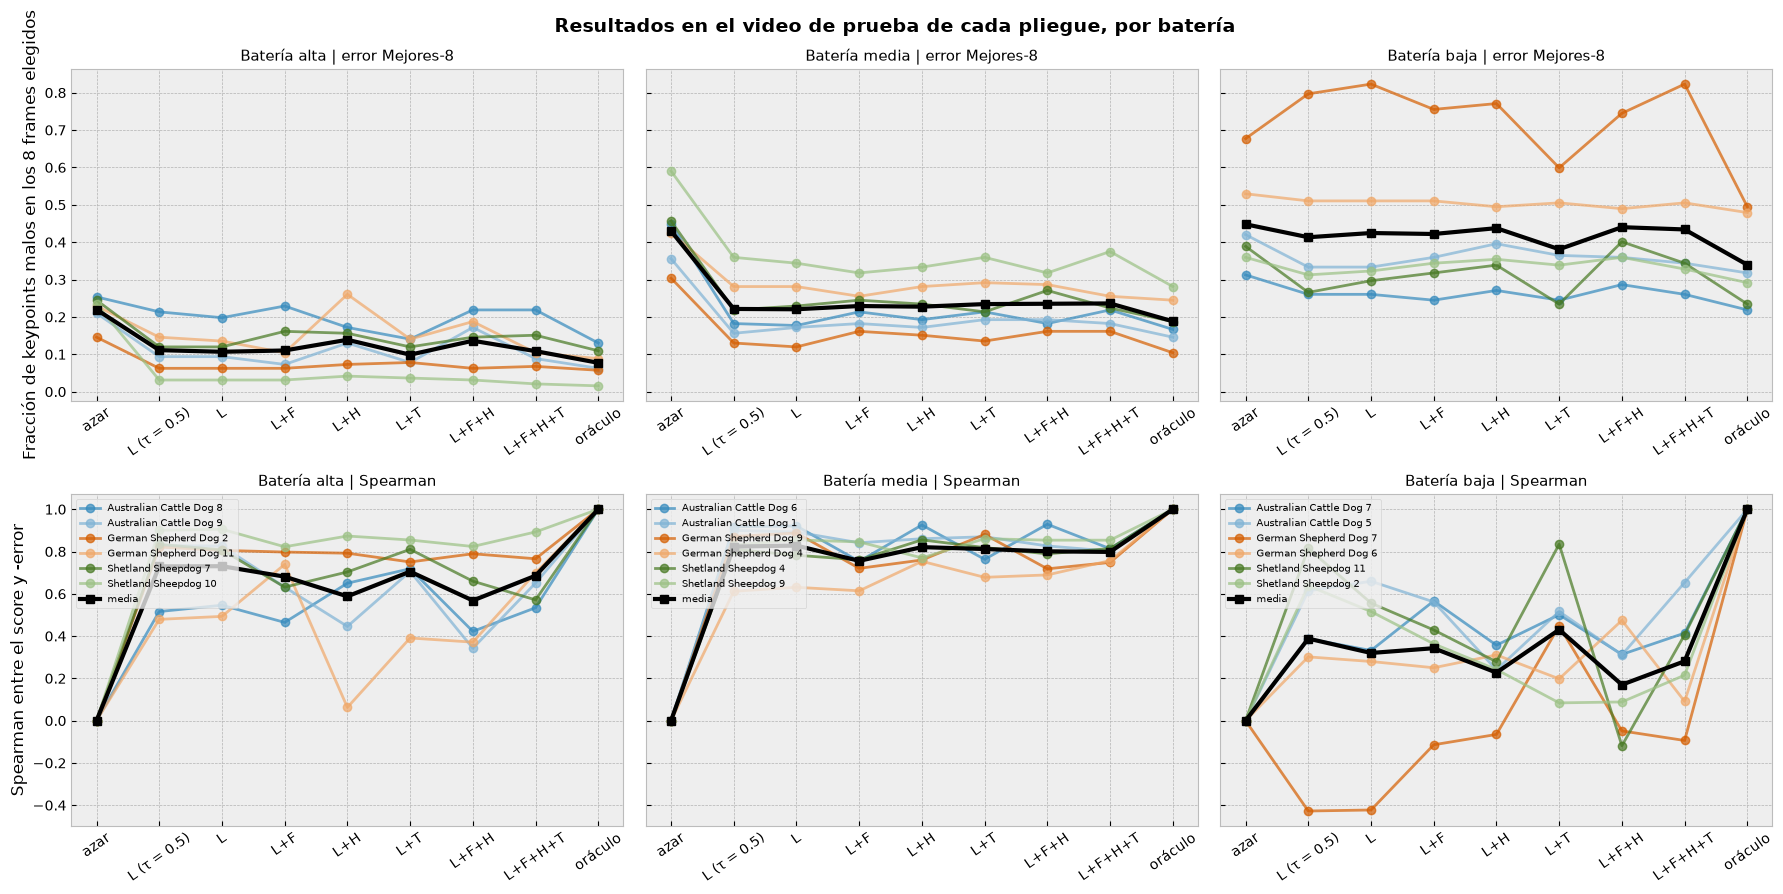

In [29]:
with plt.style.context('bmh'):
    fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey='row')
    paleta = ['#348ABD', '#7FB3D5', '#D55E00', '#F0A868', '#467821', '#9BC184']   # dos tonos por raza
    for j, (b, lista) in enumerate(BATERIAS.items()):
        colores = dict(zip([v for _, v in lista], paleta))
        for fila, metrica in enumerate(['error Mejores-8', 'Spearman']):
            ax = axes[fila, j]
            for video in colores:
                t = resultados[resultados.video == video].set_index('configuración').loc[ORDEN]
                ax.plot(ORDEN, t[metrica], marker='o', color=colores[video], alpha=0.7, label=video.replace('_', ' '))
            ax.plot(ORDEN, resumen.loc[b][(metrica, 'mean')], color='black', linewidth=3, marker='s', label='media')
            ax.set_title(f'Batería {b} | {metrica}', fontsize=11)
            ax.tick_params(axis='x', rotation=35)
        axes[1, j].legend(fontsize=7, loc='upper left')
    axes[0, 0].set_ylabel('Fracción de keypoints malos en los 8 frames elegidos')
    axes[1, 0].set_ylabel('Spearman entre el score y -error')
    fig.suptitle('Resultados en el video de prueba de cada pliegue, por batería', fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()

In [30]:
fig.savefig('figures/ablation_comparison.png', dpi=300, bbox_inches='tight')

En la batería alta, elegir al azar da un error Mejores-8 de 0.220, el score actual lo reduce a la mitad (0.111) y el oráculo llega a 0.077. La mejor configuración es L+T, con 0.099, mientras que las que agregan proporciones de hueso empeoran (0.139 en L+H y 0.136 en L+F+H). En la batería media, el score actual queda aún más cerca del oráculo (0.221 contra 0.188, frente a 0.430 al azar) y ninguna configuración lo mejora: todas quedan entre 0.220 y 0.236, y solo ajustar τ iguala su Spearman (0.828 contra 0.824). En la batería baja la situación cambia: el score actual apenas mejora al azar (0.413 contra 0.448) y su Spearman es de 0.388. Ahí L+T es la única configuración que ayuda, con un error Mejores-8 de 0.381 y un Spearman de 0.430, mientras que las que agregan ángulos o proporciones quedan peor (de 0.422 a 0.440). La gráfica muestra el caso extremo: en German Shepherd Dog 7, el score actual elige frames peores que el azar (cerca de 0.80 contra 0.68, con un Spearman negativo), y L+T los baja a cerca de 0.60.

### 5.2. Variabilidad

Con seis videos de prueba, la diferencia media puede deberse a uno o dos videos. En cada batería y para cada configuración se calcula la diferencia de error Mejores-8 contra el score actual en cada video, la prueba de Wilcoxon pareada sobre esas seis diferencias (cuyo valor p mínimo posible, con seis pares, es 0.031) y un intervalo de confianza del 95% por bootstrap, remuestreando los frames dentro de cada video y volviendo a elegir los 8 mejores en cada réplica:

In [31]:
rng = np.random.default_rng(SEMILLA)
pivote = resultados.pivot(index='video', columns='configuración', values='error Mejores-8')
replicas = [{v: rng.integers(0, (anotados.video == v).sum(), (anotados.video == v).sum()) for _, _, v in TODOS} for _ in range(2000)]

def error_top(s, error):
    return error[np.argsort(-s, kind='stable')[:K_SEL]].mean()

variabilidad = []

for bateria, lista in BATERIAS.items():
    videos_b = [v for _, v in lista]
    
    for nombre in CONFIGURACIONES:
        dif = pivote.loc[videos_b, nombre] - pivote.loc[videos_b, 'L (τ = 0.5)']
        boot = []
        
        for r in replicas:
            d = []
            
            for v in videos_b:
                e = anotados.error.to_numpy()[anotados.video == v][r[v]]
                d.append(error_top(puntajes[(v, nombre)][r[v]], e) - error_top(puntajes[(v, 'L (τ = 0.5)')][r[v]], e))

                
            boot.append(np.mean(d))
            
        p = wilcoxon(dif).pvalue if (dif != 0).any() else 1.0
        
        variabilidad.append({'batería': bateria, 'configuración': nombre, 'diferencia media': dif.mean(), 'videos que mejoran': (dif < 0).sum(),
                             'videos que empeoran': (dif > 0).sum(), 'p Wilcoxon': p,
                             'IC 95% inferior': np.percentile(boot, 2.5), 'IC 95% superior': np.percentile(boot, 97.5)})

        
variabilidad = pd.DataFrame(variabilidad).set_index(['batería', 'configuración'])
variabilidad.round(3)

diferencia media  videos que mejoran  \
batería configuración                                         
alta    L                        -0.004                   2   
        L+F                      -0.001                   2   
        L+H                       0.028                   1   
        L+T                      -0.012                   3   
        L+F+H                     0.025                   0   
        L+F+H+T                  -0.003                   3   
media   L                        -0.001                   3   
        L+F                       0.008                   2   
        L+H                       0.006                   1   
        L+T                       0.013                   1   
        L+F+H                     0.014                   1   
        L+F+H+T                   0.015                   1   
baja    L                         0.011                   0   
        L+F                       0.009                   2   
        L+H                       0.024                   2   
        L+T                      -0.032                   4   
        L+F+H                     0.027                   2   
        L+F+H+T                   0.021                   2   

                       videos que empeoran  p Wilcoxon  IC 95% inferior  \
batería configuración                                                     
alta    L                                0       0.500           -0.010   
        L+F                              3       1.000           -0.021   
        L+H                              5       0.312           -0.003   
        L+T                              2       0.812           -0.022   
        L+F+H                            5       0.062           -0.002   
        L+F+H+T                          3       0.688           -0.023   
media   L                                2       1.000           -0.014   
        L+F                              4       0.500           -0.010   
        L+H                              4       0.625           -0.016   
        L+T                              4       0.125           -0.013   
        L+F+H                            4       0.438           -0.010   
        L+F+H+T                          5       0.156           -0.007   
baja    L                                4       0.125           -0.008   
        L+F                              3       0.625           -0.030   
        L+H                              4       0.312           -0.012   
        L+T                              2       0.625           -0.073   
        L+F+H                            4       0.438           -0.013   
        L+F+H+T                          4       0.156           -0.016   

                       IC 95% superior  
batería configuración                   
alta    L                        0.010  
        L+F                      0.026  
        L+H                      0.044  
        L+T                      0.007  
        L+F+H                    0.050  
        L+F+H+T                  0.018  
media   L                        0.016  
        L+F                      0.038  
        L+H                      0.036  
        L+T                      0.033  
        L+F+H                    0.043  
        L+F+H+T                  0.038  
baja    L                        0.036  
        L+F                      0.038  
        L+H                      0.042  
        L+T                     -0.007  
        L+F+H                    0.043  
        L+F+H+T                  0.037

In [32]:
variabilidad.to_csv('figures/variability.csv')

En las baterías alta y media ninguna diferencia es significativa. En la alta, L+T reduce el error Mejores-8 en 0.012, pero mejora en tres videos y empeora en dos (p = 0.812), y L+F+H empeora en cinco de seis (p = 0.062). En la media, todas las configuraciones salvo L empeoran en cuatro o cinco videos, aunque sin significancia. En la batería baja, L+T reduce el error Mejores-8 en 0.032 y mejora en cuatro videos y empeora en dos (p = 0.625), pero su intervalo de bootstrap, de -0.073 a -0.007, no incluye el cero. Las dos pruebas responden preguntas distintas: el bootstrap remuestrea los frames dentro de cada video, por lo que indica que la mejora es estable en esos seis videos, mientras que Wilcoxon compara los videos entre sí e indica que no se puede afirmar que se repita en otros. Con seis videos por batería, solo una mejora que se diera en todos sería significativa.

### 5.3. Aporte de cada parámetro

La comparación de configuraciones mide el aporte de cada grupo. Para medir el de cada parámetro, se toma la configuración completa con los pesos ajustados en cada pliegue, se anula el peso de un parámetro a la vez sin volver a ajustar y se mide el cambio en el video de prueba, promediado en cada batería. Un cambio positivo en error Mejores-8, o negativo en Spearman, indica que el parámetro ayudaba:

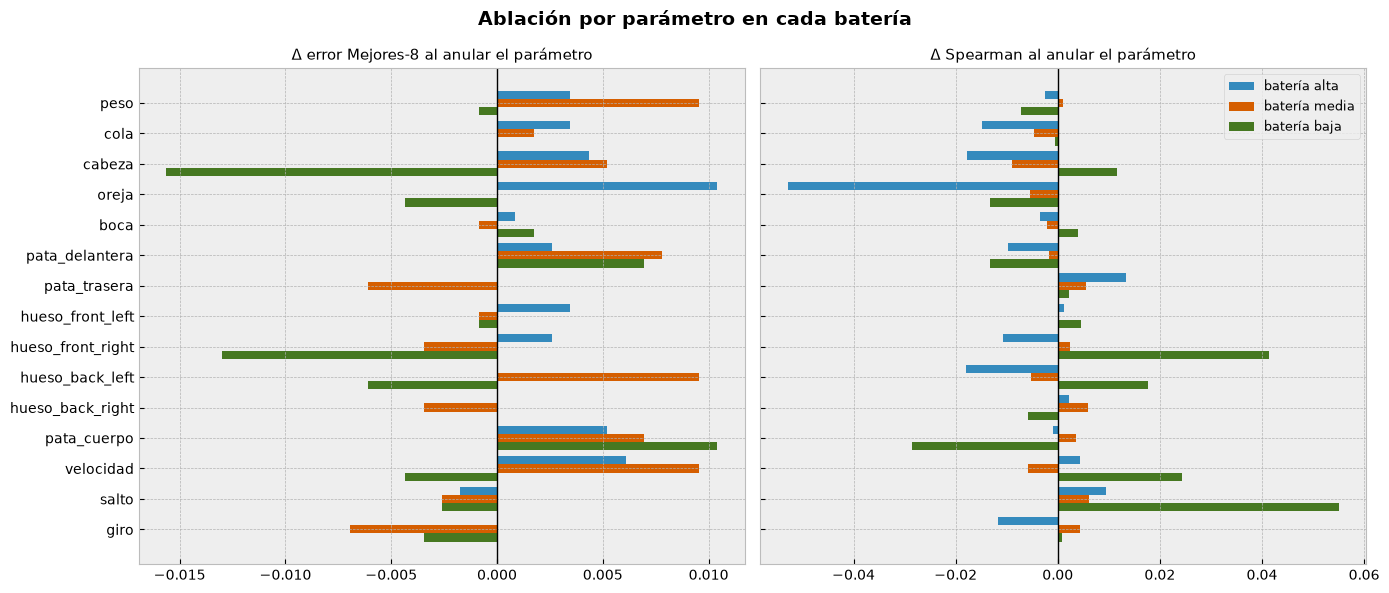

In [33]:
ablacion = []

for bateria, raza, prueba in TODOS:
    filas = anotados[anotados.video == prueba]
    p = pesos[(prueba, 'L+F+H+T')]
    D = DATOS[p['tau']].iloc[filas.index.to_numpy()]
    base = evaluar(puntaje(D, p, ['F', 'H', 'T']), filas)
    
    for c in [c for cols in GRUPOS.values() for c in cols]:
        m = evaluar(puntaje(D, {**p, f'w_{c}': 0.0}, ['F', 'H', 'T']), filas)
        ablacion.append({'batería': bateria, 'video': prueba, 'parámetro': c, 'Δ error Mejores-8': m['error Mejores-8'] - base['error Mejores-8'],
                         'Δ Spearman': m['Spearman'] - base['Spearman']})

        
ablacion = (pd.DataFrame(ablacion).groupby(['parámetro', 'batería'], sort=False)[['Δ error Mejores-8', 'Δ Spearman']].mean()
            .unstack('batería')[[(m, b) for m in ['Δ error Mejores-8', 'Δ Spearman'] for b in BATERIAS]])

with plt.style.context('bmh'):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
    y = np.arange(len(ablacion))
    
    for ax, metrica in zip(axes, ['Δ error Mejores-8', 'Δ Spearman']):
        for k, (b, color) in enumerate(zip(BATERIAS, ['#348ABD', '#D55E00', '#467821'])):
            ax.barh(y + (k - 1) * 0.27, ablacion[(metrica, b)], height=0.27, color=color, label=f'batería {b}')
            
        ax.axvline(0, color='black', linewidth=1)
        ax.set_title(f'{metrica} al anular el parámetro', fontsize=11)
        
    axes[0].set_yticks(y, ablacion.index)
    axes[0].invert_yaxis()
    axes[1].legend(fontsize=9)
    fig.suptitle('Ablación por parámetro en cada batería', fontweight='bold', fontsize=14)
    plt.tight_layout()
    
    plt.show()

In [34]:
ablacion.to_csv('figures/ablation_parameters.csv')
fig.savefig('figures/ablation_parameters.png', dpi=300, bbox_inches='tight')

En las tres baterías, anular un parámetro cambia el error Mejores-8 en menos de 0.016, mucho menos que la diferencia entre videos, y los parámetros que más sostienen la configuración completa cambian de una batería a otra. En la alta destaca el ángulo de la oreja (0.010); en la media, el peso, la proporción de la pata trasera izquierda y la velocidad (0.010 cada uno), y en la baja, la razón pata-cuerpo (0.010) y el ángulo de la pata delantera (0.007). La razón pata-cuerpo (0.005, 0.007 y 0.010) y el ángulo de la pata delantera (0.003, 0.008 y 0.007) son los únicos parámetros que reducen el error Mejores-8 en las tres baterías. En la batería baja, anular el ángulo de la cabeza o la proporción de la pata delantera derecha reduce el error Mejores-8, y anular el salto sube el Spearman en 0.055, de modo que esos parámetros agregan ruido en la combinación aunque por separado se correlacionen con el error.

### 5.4. Resultados por raza

Para responder la tercera pregunta, se promedia el error Mejores-8 de los dos videos de cada raza en cada batería:

In [35]:
por_raza = resultados.pivot_table(index='configuración', columns=['batería', 'raza'], values='error Mejores-8', aggfunc='mean').loc[ORDEN, list(BATERIAS)]
por_raza.round(3)

batería                        alta                                        \
raza          Australian_Cattle_Dog German_Shepherd_Dog Shetland_Sheepdog   
configuración                                                               
azar                          0.232               0.188             0.240   
L (τ = 0.5)                   0.154               0.104             0.076   
L                             0.146               0.099             0.076   
L+F                           0.151               0.083             0.096   
L+H                           0.151               0.167             0.099   
L+T                           0.109               0.109             0.078   
L+F+H                         0.195               0.125             0.089   
L+F+H+T                       0.154               0.086             0.086   
oráculo                       0.096               0.073             0.062   

batería                       media                                        \
raza          Australian_Cattle_Dog German_Shepherd_Dog Shetland_Sheepdog   
configuración                                                               
azar                          0.402               0.365             0.523   
L (τ = 0.5)                   0.169               0.206             0.289   
L                             0.174               0.201             0.286   
L+F                           0.198               0.208             0.281   
L+H                           0.182               0.216             0.284   
L+T                           0.203               0.214             0.286   
L+F+H                         0.188               0.224             0.294   
L+F+H+T                       0.201               0.208             0.299   
oráculo                       0.156               0.174             0.234   

batería                        baja                                        
raza          Australian_Cattle_Dog German_Shepherd_Dog Shetland_Sheepdog  
configuración                                                              
azar                          0.366               0.603             0.374  
L (τ = 0.5)                   0.297               0.654             0.289  
L                             0.297               0.667             0.310  
L+F                           0.302               0.633             0.331  
L+H                           0.333               0.633             0.346  
L+T                           0.305               0.552             0.286  
L+F+H                         0.323               0.617             0.380  
L+F+H+T                       0.302               0.664             0.336  
oráculo                       0.268               0.487             0.263

In [36]:
por_raza.to_csv('figures/breed_results.csv')

El aporte por raza no se mantiene entre baterías. En la alta, la dinámica ayuda en Australian Cattle Dog (de 0.154 a 0.109) y los ángulos en German Shepherd Dog (de 0.104 a 0.083), mientras que en Shetland Sheepdog nada mejora al score actual. En la media, ninguna configuración mejora de forma apreciable en ninguna raza: el mejor caso es L+F en Shetland Sheepdog (de 0.289 a 0.281). En la baja, la dinámica ayuda sobre todo en German Shepherd Dog (de 0.654 a 0.552), por el video en el que la likelihood falla, y casi nada en las otras dos razas. Como el patrón de una raza cambia según la batería, las diferencias parecen depender más de las condiciones de cada video que de la morfología de la raza.

### 5.5. Análisis de error

In [37]:
# Batería alta, la del caso de la sección 2.3
MEJOR = resumen.loc['alta'].loc[list(CONFIGURACIONES), ('error Mejores-8', 'mean')].idxmin()
cambios = []

for raza, prueba in VIDEOS_SEL:
    filas = anotados[anotados.video == prueba].reset_index()
    top_l = set(np.argsort(-puntajes[(prueba, 'L (τ = 0.5)')], kind='stable')[:K_SEL])
    top_m = set(np.argsort(-puntajes[(prueba, MEJOR)], kind='stable')[:K_SEL])
    
    for j in top_l ^ top_m:
        cambios.append({'video': prueba, 'frame': filas.frame[j], 'índice': filas['index'][j],
                        'elegido por': 'solo L (τ = 0.5)' if j in top_l else f'solo {MEJOR}', 'error': filas.error[j]})


cambios = pd.DataFrame(cambios)
print(f"Mejor configuración: {MEJOR}; frames intercambiados: {len(cambios) // 2} por cada score, de {K_SEL * len(VIDEOS_SEL)}")

filas = anotados[anotados.video == caso.video]

j = int(np.flatnonzero(filas.frame.to_numpy() == caso.frame)[0])

for nombre in dict.fromkeys(['L (τ = 0.5)', MEJOR, 'L+H', 'L+F+H']):
    lugar = (puntajes[(caso.video, nombre)] > puntajes[(caso.video, nombre)][j]).sum() + 1
    print(f"Frame {int(caso.frame)} de {caso.video}: lugar {lugar} de {len(filas)} con {nombre}")

descartados = cambios[cambios['elegido por'] == 'solo L (τ = 0.5)']
dev = DATOS[0.5].iloc[descartados['índice']][[c for cols in GRUPOS.values() for c in cols]]


print("Parámetros con mayor desviación media en los frames que descarta la mejor configuración:")
print(dev.mean().sort_values(ascending=False).head(5).round(2).to_string())

resumen_cambios = cambios.groupby('elegido por').agg(frames=('error', 'count'), error_medio=('error', 'mean'), error_mediano=('error', 'median'))
resumen_cambios.round(3)

Mejor configuración: L+T; frames intercambiados: 10 por cada score, de 48
Frame 590 de Shetland_Sheepdog_7: lugar 12 de 24 con L (τ = 0.5)
Frame 590 de Shetland_Sheepdog_7: lugar 12 de 24 con L+T
Frame 590 de Shetland_Sheepdog_7: lugar 6 de 24 con L+H
Frame 590 de Shetland_Sheepdog_7: lugar 9 de 24 con L+F+H
Parámetros con mayor desviación media en los frames que descarta la mejor configuración:
velocidad           2.02
cabeza              1.29
hueso_front_left    1.20
boca                1.03
giro                1.02


,frames,error_medio,error_mediano
elegido por,,,
solo L (τ = 0.5),10,0.179,0.146
solo L+T,10,0.121,0.146


En la batería alta, L+T cambia 10 de los 48 frames que elige el score actual. Los 10 frames que solo elige el score actual tienen un error medio de 0.179, y los 10 que solo elige L+T, de 0.121, con la misma mediana (0.146): la ganancia viene de evitar algunos frames muy malos más que de mejorar los típicos. Los frames que L+T descarta tienen, sobre todo, una velocidad atípica (desviación media de 2.02), es decir, el perro se movía rápido, que es cuando la sección 2.4 mostró que los keypoints necesitan más corrección. El frame de la sección 2.3 ocupa el lugar 12 de 24 con el score actual y con L+T, pero sube al 6 con L+H y al 9 con L+F+H: la proporción contra la referencia del video no penaliza la pata desproporcionada que se veía dentro del frame, lo que coincide con el bajo aporte del grupo H.

## 6. Conclusiones

Agregar los ángulos de Ferres y las proporciones de hueso al score actual no elige frames con menor error real en ninguna de las tres baterías. En los videos de calidad alta y media, la likelihood ya es un criterio fuerte: reduce a la mitad el error de elegir al azar, su correlación con el error es de -0.73 y -0.82, y en la batería media queda muy cerca del oráculo. Ahí los parámetros posturales dicen poco que la likelihood no diga ya, porque los frames con poses atípicas suelen ser también los de likelihood baja.

Los videos de calidad baja muestran el otro lado. En ellos el modelo está igual de seguro que en los buenos, pero se equivoca mucho más, y la likelihood apenas mejora la elección al azar; en un video llega a elegir frames peores que el azar. Es justo donde los parámetros aportan más información, pero los ángulos y las proporciones están diseñados para vistas laterales y en esos videos casi no se pueden calcular. La dinámica, que no depende de la vista, es el único grupo que ayuda: baja el error Mejores-8 de 0.413 a 0.381, con una mejora estable dentro de los videos pero que no se repite en todos (p = 0.625).

Entre los grupos, la dinámica es la única con una tendencia favorable, en las baterías alta y baja; los ángulos son neutros y las proporciones de hueso restan. Entre los parámetros, los que más sostienen la configuración completa cambian de una batería a otra, y solo la razón pata-cuerpo y el ángulo de la pata delantera ayudan en las tres. El aporte por raza tampoco se mantiene entre baterías, por lo que las diferencias parecen depender más de las condiciones de cada video que de la morfología.

Hay cuatro limitaciones importantes. Las baterías se formaron con criterios calculados a partir de la corrección, y cada una tiene solo seis videos, por lo que la prueba de Wilcoxon solo detectaría una mejora que se repitiera en todos y, con 18 comparaciones, algún resultado favorable podría deberse al azar. En las tres baterías, los frames anotados son en su mayoría frames que el score actual ya prefería (percentil mediano cerca de 80), así que no se puede medir qué pasa en el resto del video. La atipicidad respecto al propio video penaliza también posturas reales poco frecuentes. Por último, `neck_end` aproxima la cruz y `tail_base` no tiene sustituto, lo que deja sin calcular varios ángulos.

El *notebook* queda como base para estudios de ablación posteriores: cada grupo de parámetros es una lista en `GRUPOS`, cada batería una lista en `BATERIAS`, y agregar un parámetro solo requiere calcularlo en `parametros_video`. Los siguientes pasos serían agregar parámetros dinámicos e independientes de la vista, anotar frames de score bajo y comprobar si un score ajustado en videos buenos funciona en los difíciles.

## Referencias

Ferres, K., Schloesser, T., & Gloor, P. A. (2022). Predicting dog emotions based on posture analysis using DeepLabCut. *Future Internet, 14*(4), 97. https://doi.org/10.3390/fi14040097

Nath, T., Mathis, A., Chen, A. C., Patel, A., Bethge, M., & Mathis, M. W. (2019). Using DeepLabCut for 3D markerless pose estimation across species and behaviors. *Nature Protocols, 14*, 2152-2176. https://doi.org/10.1038/s41596-019-0176-0

## Declaración de Uso de IA Generativa

Para este proyecto se utilizó Claude para implementar el score combinado con su ajuste en Optuna, la evaluación con bootstrap y la prueba de Wilcoxon, y la repetición del análisis en las tres baterías de videos. También se utilizó para corregir errores de ortografía y de redacción de los comentarios añadidos al código. El REDME.md del proyecto fue generado utilizando el modelo. 